# Limpieza, análisis exploratorio y segmentación de HMEQ
Este notebook revisa solicitudes de crédito, documenta la ausencia de datos y exporta grupos exploratorios.
La limpieza elimina primero las filas sin información en las ocho variables acordadas y después las que tienen cuatro o más nulos entre ellas.
Las imputaciones finales se aplican después de comparar sus efectos estadísticos y sus gráficos.
`BAD` se utiliza para describir resultados históricos y queda fuera del ajuste de K-means.

## 1. Bibliotecas de análisis
Importamos pandas y NumPy para las tablas y los cálculos, y Matplotlib y Seaborn para el EDA.
`display` presenta tablas y texto dentro del notebook. `run` permite crear carpetas con PowerShell.
Las rutas del proyecto se escriben como cadenas relativas al directorio de trabajo `notebooks`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from subprocess import CREATE_NO_WINDOW, run

Importamos las pruebas, métricas y transformaciones que se utilizan más adelante.
K-means se ajustará sobre una matriz numérica; no se realiza ninguna reducción de dimensiones.
Los límites de hilos y memoria controlan los recursos de los cálculos de distancias.

In [2]:
from scipy.stats import chi2_contingency, false_discovery_control, binomtest, wasserstein_distance
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import silhouette_samples
from sklearn import config_context
from threadpoolctl import threadpool_limits

Configuramos rutas relativas para ejecutar con `notebooks` como directorio de trabajo.
`../` sube a la raíz del proyecto: permite leer `input/hmeq.csv` y escribir en `outputs`.
PowerShell crea la carpeta de salida si hace falta. Las rutas se mantienen como cadenas de texto.
La semilla permite repetir las particiones y las inicializaciones con el mismo entorno.

In [3]:
ruta_entrada = '../input/hmeq.csv'
ruta_outputs = '../outputs'
comando_outputs = f"New-Item -ItemType Directory -Force '{ruta_outputs}' | Out-Null"
run(['powershell', '-NoProfile', '-Command', comando_outputs], check=True, capture_output=True, text=True, creationflags=CREATE_NO_WINDOW)


pd.set_option('display.max_columns', None)
pd.set_option('io.parquet.engine', 'fastparquet')
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 11, 'axes.labelsize': 10})
semilla = 865
numericas = ['LOAN', 'MORTDUE', 'VALUE', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']
categoricas = ['REASON', 'JOB']
conteos = ['DEROG', 'DELINQ', 'NINQ', 'CLNO']

## 2. Carga y referencia original
Leemos el CSV sin modificarlo y comprobamos el tamaño original de 5960 solicitudes.
`BAD` indica impago o mora grave; `LOAN`, `MORTDUE` y `VALUE` son montos.
`YOJ` está en años y `CLAGE` en meses. Los conteos no representan magnitudes continuas.
El índice original, que empieza en cero, permitirá recuperar cada registro mediante `ID_FILA`.
[Diccionario de HMEQ](https://www.creditriskanalytics.net/datasets-private2.html)

In [4]:
datita_original = pd.read_csv(ruta_entrada)
tamanio_original = 5960
assert len(datita_original) == tamanio_original
assert datita_original.columns.tolist() == ['BAD', 'LOAN', 'MORTDUE', 'VALUE', 'REASON', 'JOB', 'YOJ', 'DEROG', 'DELINQ', 'CLAGE', 'NINQ', 'CLNO', 'DEBTINC']


display(datita_original.head(15))
display(datita_original.describe())
datita_original.info()

<class 'pandas.DataFrame'>
RangeIndex: 5960 entries, 0 to 5959
Data columns (total 13 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   BAD      5960 non-null   int64  
 1   LOAN     5960 non-null   int64  
 2   MORTDUE  5442 non-null   float64
 3   VALUE    5848 non-null   float64
 4   REASON   5708 non-null   str    
 5   JOB      5681 non-null   str    
 6   YOJ      5445 non-null   float64
 7   DEROG    5252 non-null   float64
 8   DELINQ   5380 non-null   float64
 9   CLAGE    5652 non-null   float64
 10  NINQ     5450 non-null   float64
 11  CLNO     5738 non-null   float64
 12  DEBTINC  4693 non-null   float64
dtypes: float64(9), int64(2), str(2)
memory usage: 675.4 KB


,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
0,1,1100,25860.0,39025.0,HomeImp,Other,10.5,0.0,0.0,94.366667,1.0,9.0,NaN
1,1,1300,70053.0,68400.0,HomeImp,Other,7.0,0.0,2.0,121.833333,0.0,14.0,NaN
2,1,1500,13500.0,16700.0,HomeImp,Other,4.0,0.0,0.0,149.466667,1.0,10.0,NaN
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,0,1700,97800.0,112000.0,HomeImp,Office,3.0,0.0,0.0,93.333333,0.0,14.0,NaN
5,1,1700,30548.0,40320.0,HomeImp,Other,9.0,0.0,0.0,101.466002,1.0,8.0,37.113614
6,1,1800,48649.0,57037.0,HomeImp,Other,5.0,3.0,2.0,77.100000,1.0,17.0,NaN
7,1,1800,28502.0,43034.0,HomeImp,Other,11.0,0.0,0.0,88.766030,0.0,8.0,36.884894
8,1,2000,32700.0,46740.0,HomeImp,Other,3.0,0.0,2.0,216.933333,1.0,12.0,NaN
9,1,2000,NaN,62250.0,HomeImp,Sales,16.0,0.0,0.0,115.800000,0.0,13.0,NaN


,BAD,LOAN,MORTDUE,VALUE,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
count,5960.000000,5960.000000,5442.000000,5848.000000,5445.000000,5252.000000,5380.000000,5652.000000,5450.000000,5738.000000,4693.000000
mean,0.199497,18607.969799,73760.817200,101776.048741,8.922268,0.254570,0.449442,179.766275,1.186055,21.296096,33.779915
std,0.399656,11207.480417,44457.609458,57385.775334,7.573982,0.846047,1.127266,85.810092,1.728675,10.138933,8.601746
min,0.000000,1100.000000,2063.000000,8000.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.524499
25%,0.000000,11100.000000,46276.000000,66075.500000,3.000000,0.000000,0.000000,115.116702,0.000000,15.000000,29.140031
50%,0.000000,16300.000000,65019.000000,89235.500000,7.000000,0.000000,0.000000,173.466667,1.000000,20.000000,34.818262
75%,0.000000,23300.000000,91488.000000,119824.250000,13.000000,0.000000,0.000000,231.562278,2.000000,26.000000,39.003141
max,1.000000,89900.000000,399550.000000,855909.000000,41.000000,10.000000,15.000000,1168.233561,17.000000,71.000000,203.312149


## 3. Primer filtro: ausencia simultánea en ocho variables
`isna()` identifica los nulos y `all(axis=1)` exige que falten las ocho columnas en la misma fila.
La negación `~` conserva las demás solicitudes para aplicarles después el segundo filtro.
Este primer paso elimina cuatro filas y conserva su índice original para auditar la selección.

In [5]:
columnas_eliminacion = ['VALUE', 'CLAGE', 'NINQ', 'CLNO', 'YOJ', 'DEROG', 'DELINQ', 'DEBTINC']
filas_eliminadas_iniciales = datita_original[columnas_eliminacion].isna().all(axis=1)
datita_intermedia = datita_original.loc[~filas_eliminadas_iniciales].copy(deep=True)
cantidad_eliminada_inicial = int(filas_eliminadas_iniciales.sum())


display(datita_original.loc[filas_eliminadas_iniciales].rename_axis('ID_FILA'))
print(f'Primer filtro: {cantidad_eliminada_inicial} filas eliminadas; quedan {len(datita_intermedia)}.')

Primer filtro: 4 filas eliminadas; quedan 5956.


,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC
ID_FILA,,,,,,,,,,,,,
3,1,1500,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1144,1,10000,NaN,NaN,HomeImp,Other,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1405,0,10800,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1553,1,11300,NaN,NaN,HomeImp,Other,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Segundo filtro: cuatro o más nulos entre las mismas ocho variables
Contamos los nulos por fila sobre `datita_intermedia`, antes de imputar cualquier valor.
`ge(4)` identifica las solicitudes con al menos cuatro ausencias en las columnas acordadas.
Eliminamos esas filas adicionales y unimos ambas máscaras para auditar el descarte total.
`MORTDUE`, `REASON` y `JOB` no intervienen en este conteo.

In [6]:
nulos_por_fila = datita_intermedia[columnas_eliminacion].isna().sum(axis=1)
filas_eliminadas_adicionales = nulos_por_fila.ge(4)
datita_base = datita_intermedia.loc[~filas_eliminadas_adicionales].copy(deep=True)
cantidad_eliminada_adicional = int(filas_eliminadas_adicionales.sum())
filas_eliminadas = filas_eliminadas_iniciales | filas_eliminadas_adicionales.reindex(datita_original.index, fill_value=False)
cantidad_eliminada = int(filas_eliminadas.sum())
porcentaje_eliminado = cantidad_eliminada / tamanio_original * 100


assert cantidad_eliminada == cantidad_eliminada_inicial + cantidad_eliminada_adicional
assert len(datita_base) + cantidad_eliminada == tamanio_original
assert datita_base[columnas_eliminacion].isna().sum(axis=1).lt(4).all()
print(f'Segundo filtro: {cantidad_eliminada_adicional} filas adicionales; quedan {len(datita_base)}.')

Segundo filtro: 279 filas adicionales; quedan 5677.


Resumimos cada filtro y el descarte acumulado con porcentajes respecto a las 5960 filas originales.
La segunda etapa se calcula sobre las filas que superaron la primera, por lo que no cuenta dos veces las mismas solicitudes.
Mostramos también el porcentaje del segundo filtro respecto a su entrada de 5956 filas.
El conjunto conservado contiene como máximo tres nulos por fila entre las ocho variables del filtro.

In [7]:
resumen_eliminacion = pd.DataFrame({'filas': [tamanio_original, cantidad_eliminada_inicial, cantidad_eliminada_adicional, cantidad_eliminada, len(datita_base)]}, index=['Original', 'Primer filtro', 'Segundo filtro adicional', 'Total eliminadas', 'Conservadas'])
resumen_eliminacion['porcentaje_original'] = resumen_eliminacion['filas'] / tamanio_original * 100


display(resumen_eliminacion.round(4))
print(f'Se eliminaron {cantidad_eliminada} de {tamanio_original} filas ({porcentaje_eliminado:.4f} %). Quedan {len(datita_base)} filas.')
print(f'El segundo filtro representa {cantidad_eliminada_adicional / len(datita_intermedia) * 100:.4f} % de las filas que recibio.')

Se eliminaron 283 de 5960 filas (4.7483 %). Quedan 5677 filas.
El segundo filtro representa 4.6844 % de las filas que recibio.


,filas,porcentaje_original
Original,5960,100.0000
Primer filtro,4,0.0671
Segundo filtro adicional,279,4.6812
Total eliminadas,283,4.7483
Conservadas,5677,95.2517


Comparamos los nulos antes y después de ambos filtros, con el denominador de cada muestra.
Desde aquí, el EDA y las estadísticas de imputación utilizan las 5677 filas de `datita_base`.
Las variables a comparar y las banderas se definen por los nulos del CSV original para mantener el esquema de auditoría.
Así `CLNO` conserva su comparación y una bandera de ausencia constante en cero, porque ya no tiene nulos.

In [8]:
comparacion_nulos = pd.DataFrame({'nulos_originales': datita_original.isna().sum(), 'pct_original': datita_original.isna().mean() * 100, 'nulos_conservados': datita_base.isna().sum(), 'pct_conservado': datita_base.isna().mean() * 100})
numericas_a_comparar = [variable for variable in numericas if datita_original[variable].isna().any()]
variables_con_banderas = datita_original.columns[datita_original.isna().any()].tolist()


display(comparacion_nulos.round(3))
display(pd.Series({'bad_original_pct': datita_original['BAD'].mean() * 100, 'bad_eliminadas_pct': datita_original.loc[filas_eliminadas, 'BAD'].mean() * 100, 'bad_conservadas_pct': datita_base['BAD'].mean() * 100}))

,nulos_originales,pct_original,nulos_conservados,pct_conservado
BAD,0,0.000,0,0.000
LOAN,0,0.000,0,0.000
MORTDUE,518,8.691,387,6.817
VALUE,112,1.879,89,1.568
REASON,252,4.228,166,2.924
JOB,279,4.681,147,2.589
YOJ,515,8.641,351,6.183
DEROG,708,11.879,427,7.522
DELINQ,580,9.732,298,5.249
CLAGE,308,5.168,86,1.515


bad_original_pct       19.949664
bad_eliminadas_pct     20.494700
bad_conservadas_pct    19.922494
dtype: float64

## 4. Calidad y estadística descriptiva
Calculamos dispersión, asimetría, ceros y límites de 1,5 veces el rango intercuartílico sobre los datos observados.
La regla del IQR señala casos para revisión; no elimina automáticamente extremos ni conteos positivos.
Cuando el IQR vale cero, los valores positivos pueden quedar señalados por la propia concentración de ceros.
[Asimetría](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35b.htm) y [atípicos](https://www.itl.nist.gov/div898/handbook/eda/section3/eda35h.htm), NIST.

In [9]:
estadisticas = datita_base[numericas].describe().T
estadisticas['nulos'] = datita_base[numericas].isna().sum()
estadisticas['nulos_pct'] = datita_base[numericas].isna().mean() * 100
estadisticas['ceros_observados_pct'] = datita_base[numericas].eq(0).sum() / datita_base[numericas].notna().sum() * 100
estadisticas['asimetria'] = datita_base[numericas].skew()
estadisticas['iqr'] = estadisticas['75%'] - estadisticas['25%']
estadisticas['limite_inferior_iqr'] = estadisticas['25%'] - 1.5 * estadisticas['iqr']
estadisticas['limite_superior_iqr'] = estadisticas['75%'] + 1.5 * estadisticas['iqr']
estadisticas['fuera_iqr'] = datita_base[numericas].lt(estadisticas['limite_inferior_iqr']).sum() + datita_base[numericas].gt(estadisticas['limite_superior_iqr']).sum()
display(estadisticas.round(3))

,count,mean,std,min,25%,50%,75%,max,nulos,nulos_pct,ceros_observados_pct,asimetria,iqr,limite_inferior_iqr,limite_superior_iqr,fuera_iqr
LOAN,5677.0,18862.991,11315.001,1100.000,11400.000,16500.000,23500.000,89900.000,0,0.000,0.000,2.021,12100.000,-6750.000,41650.000,256
MORTDUE,5290.0,74012.994,44782.681,2063.000,46401.500,65000.000,92371.500,399550.000,387,6.817,0.000,1.814,45970.000,-22553.500,161326.500,225
VALUE,5588.0,102783.767,57950.357,8000.000,66684.500,89908.500,120615.500,855909.000,89,1.568,0.000,3.064,53931.000,-14212.000,201512.000,308
YOJ,5326.0,8.969,7.605,0.000,3.000,7.000,13.000,41.000,351,6.183,7.529,0.981,10.000,-12.000,28.000,91
DEROG,5250.0,0.253,0.842,0.000,0.000,0.000,0.000,10.000,427,7.522,86.229,5.336,0.000,0.000,0.000,723
DELINQ,5379.0,0.449,1.127,0.000,0.000,0.000,0.000,15.000,298,5.249,77.691,4.025,0.000,0.000,0.000,1200
CLAGE,5591.0,179.624,85.569,0.000,115.452,173.500,230.719,1168.234,86,1.515,0.036,1.360,115.267,-57.447,403.619,53
NINQ,5445.0,1.186,1.729,0.000,0.000,1.000,2.000,17.000,232,4.087,46.446,2.621,2.000,-3.000,5.000,177
CLNO,5677.0,21.362,10.155,0.000,15.000,20.000,26.000,71.000,0,0.000,1.092,0.765,11.000,-1.500,42.500,219
DEBTINC,4489.0,33.963,8.598,0.524,29.328,34.976,39.111,203.312,1188,20.927,0.000,2.998,9.784,14.652,53.786,89


Comprobamos negativos, infinitos, conteos fraccionarios, duplicados y ausencia del objetivo.
Los conteos se revisan columna por columna para aprovechar cada valor observado.
Las comprobaciones describen la calidad; no añaden otro filtro de eliminación.

In [10]:
calidad = pd.DataFrame({'negativos': datita_base[numericas].lt(0).sum(), 'infinitos': np.isinf(datita_base[numericas]).sum()})
fraccionarios = datita_base[conteos].mod(1).ne(0) & datita_base[conteos].notna()


display(calidad)
display(fraccionarios.sum().rename('Conteos fraccionarios observados'))
display(pd.Series({'filas': len(datita_base), 'duplicados_exactos': int(datita_base.duplicated().sum()), 'casos_completos': int(datita_base.notna().all(axis=1).sum()), 'objetivos_faltantes': int(datita_base['BAD'].isna().sum())}))

,negativos,infinitos
LOAN,0,0
MORTDUE,0,0
VALUE,0,0
YOJ,0,0
DEROG,0,0
DELINQ,0,0
CLAGE,0,0
NINQ,0,0
CLNO,0,0
DEBTINC,0,0


DEROG     0
DELINQ    0
NINQ      0
CLNO      0
Name: Conteos fraccionarios observados, dtype: int64

filas                  5677
duplicados_exactos        0
casos_completos        3364
objetivos_faltantes       0
dtype: int64

Ordenamos las variables por su porcentaje de nulos en las 5677 filas conservadas.
El mapa calcula correlaciones entre indicadores 0/1 de ausencia, para ver qué datos suelen faltar juntos.
La coincidencia de nulos ayuda al diagnóstico y no demuestra la causa de la ausencia.

,nulos,porcentaje
DEBTINC,1188,20.93
DEROG,427,7.52
MORTDUE,387,6.82
YOJ,351,6.18
DELINQ,298,5.25
NINQ,232,4.09
REASON,166,2.92
JOB,147,2.59
VALUE,89,1.57
CLAGE,86,1.51


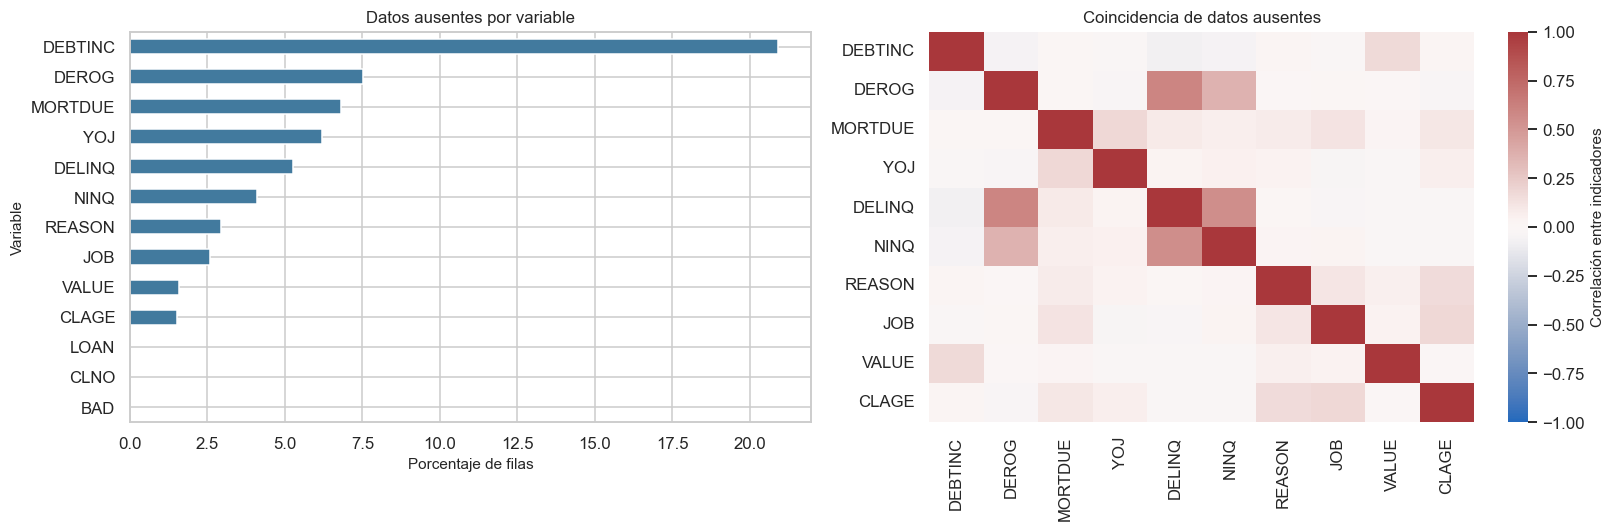

In [11]:
resumen_nulos = pd.DataFrame({'nulos': datita_base.isna().sum(), 'porcentaje': datita_base.isna().mean() * 100}).sort_values('porcentaje', ascending=False)
display(resumen_nulos.round(2))


fig, axes = plt.subplots(1, 2, figsize=(15, 5))
resumen_nulos['porcentaje'].sort_values().plot.barh(ax=axes[0], color='#427a9e')
axes[0].set(title='Datos ausentes por variable', xlabel='Porcentaje de filas', ylabel='Variable')
correlacion_ausencia = datita_base.loc[:, resumen_nulos.index[resumen_nulos['nulos'] > 0]].isna().astype(int).corr()
sns.heatmap(correlacion_ausencia, cmap='vlag', vmin=-1, vmax=1, center=0, ax=axes[1], cbar_kws={'label': 'Correlación entre indicadores'})
axes[1].set_title('Coincidencia de datos ausentes')
plt.tight_layout()
plt.show()

Comparamos `BAD=1` entre solicitudes con dato ausente y observado mediante una tabla 2×2.
La prueba chi-cuadrado contrasta independencia y phi resume la intensidad de asociación sin signo.
Los intervalos de Wilson describen la incertidumbre de cada proporción.
Benjamini-Hochberg ajusta las comparaciones múltiples; su garantía requiere independencia o dependencia positiva.
Los resultados son exploratorios y no identifican por sí solos el mecanismo MCAR, MAR o MNAR.

In [12]:
asociaciones_nulos = []
for variable in resumen_nulos.index[resumen_nulos['nulos'] > 0]:
    falta = datita_base[variable].isna()
    tabla = pd.crosstab(falta, datita_base['BAD']).reindex(index=[False, True], columns=[0, 1], fill_value=0)
    chi2, valor_p, _, _ = chi2_contingency(tabla, correction=False)
    n_ausente = int(tabla.loc[True].sum())
    n_observado = int(tabla.loc[False].sum())
    ic_ausente = binomtest(int(tabla.loc[True, 1]), n_ausente).proportion_ci(confidence_level=0.95, method='wilson')
    ic_observado = binomtest(int(tabla.loc[False, 1]), n_observado).proportion_ci(confidence_level=0.95, method='wilson')
    asociaciones_nulos.append({'variable': variable, 'n_ausente': n_ausente, 'bad_ausente_pct': tabla.loc[True, 1] / n_ausente * 100, 'ic95_ausente_inf': ic_ausente.low * 100, 'ic95_ausente_sup': ic_ausente.high * 100, 'bad_observado_pct': tabla.loc[False, 1] / n_observado * 100, 'ic95_observado_inf': ic_observado.low * 100, 'ic95_observado_sup': ic_observado.high * 100, 'phi': np.sqrt(chi2 / len(datita_base)), 'valor_p': valor_p})


asociaciones_nulos = pd.DataFrame(asociaciones_nulos).set_index('variable')
asociaciones_nulos['p_ajustado_bh'] = false_discovery_control(asociaciones_nulos['valor_p'].to_numpy(), method='bh')
tabla_asociaciones = asociaciones_nulos.sort_values('phi', ascending=False).round(4)
for columna in ['valor_p', 'p_ajustado_bh']:
    tabla_asociaciones[columna] = asociaciones_nulos[columna].map(lambda valor: f'{valor:.2e}')
display(tabla_asociaciones)

,n_ausente,bad_ausente_pct,ic95_ausente_inf,ic95_ausente_sup,bad_observado_pct,ic95_observado_inf,ic95_observado_sup,phi,valor_p,p_ajustado_bh
variable,,,,,,,,,,
DEBTINC,1188,62.3737,59.5832,65.0845,8.6879,7.8989,9.5476,0.5468,0.00e+00,0.00e+00
VALUE,89,100.0000,95.8623,100.0000,18.6471,17.6476,19.6897,0.2530,5.05e-81,2.52e-80
DEROG,427,6.7916,4.7700,9.5836,20.9905,19.9103,22.1131,0.0938,1.62e-12,5.39e-12
DELINQ,298,5.0336,3.0738,8.1379,20.7474,19.6848,21.8517,0.0877,3.82e-11,9.56e-11
NINQ,232,9.0517,5.9966,13.4408,20.3857,19.3367,21.4764,0.0562,2.31e-05,4.61e-05
JOB,147,10.2041,6.2818,16.1534,20.1808,19.1439,21.2592,0.0397,2.80e-03,4.67e-03
YOJ,351,15.0997,11.7331,19.2220,20.2403,19.1829,21.3407,0.0310,1.95e-02,2.79e-02
CLAGE,86,29.0698,20.5326,39.3968,19.7818,18.7585,20.8466,0.0284,3.23e-02,4.04e-02
REASON,166,25.9036,19.8373,33.0599,19.7423,18.7126,20.8142,0.0260,5.02e-02,5.58e-02


## 5. Objetivo y monto solicitado
Verificamos que `BAD` solo contenga 0 y 1 y describimos el desequilibrio de clases.
El histograma muestra `LOAN` y el boxplot permite comparar sus distribuciones por resultado histórico.
Estas relaciones se describen antes de la segmentación; `BAD` no interviene en las distancias de K-means.

,clientes,porcentaje
BAD,,
0,4546,80.08
1,1131,19.92


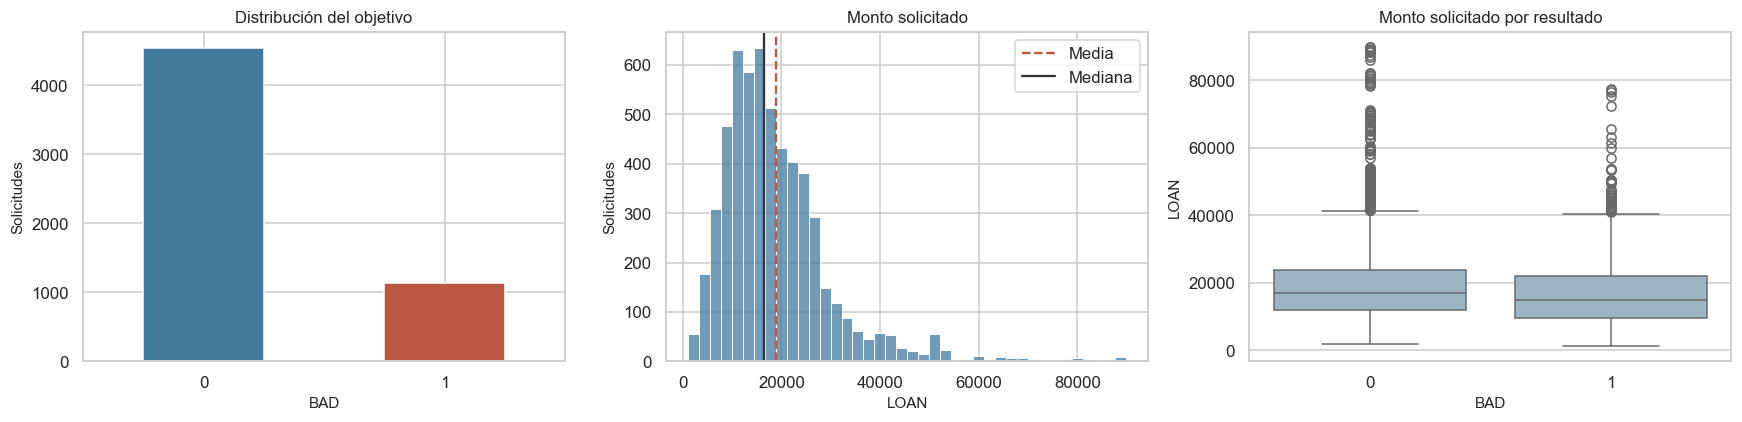

In [13]:
assert datita_base['BAD'].notna().all() and set(datita_base['BAD'].unique()) == {0, 1}
resumen_bad = datita_base['BAD'].value_counts().sort_index().to_frame('clientes')
resumen_bad['porcentaje'] = resumen_bad['clientes'] / len(datita_base) * 100
display(resumen_bad.round(2))


fig, axes = plt.subplots(1, 3, figsize=(16, 4))
resumen_bad['clientes'].plot.bar(ax=axes[0], color=['#427a9e', '#bc5742'], rot=0)
axes[0].set(title='Distribución del objetivo', xlabel='BAD', ylabel='Solicitudes')
sns.histplot(data=datita_base, x='LOAN', bins=40, ax=axes[1], color='#427a9e')
axes[1].axvline(datita_base['LOAN'].mean(), color='#bc5742', linestyle='--', label='Media')
axes[1].axvline(datita_base['LOAN'].median(), color='#333333', label='Mediana')
axes[1].set(title='Monto solicitado', xlabel='LOAN', ylabel='Solicitudes')
axes[1].legend()
sns.boxplot(data=datita_base, x='BAD', y='LOAN', ax=axes[2], color='#96b7c9')
axes[2].set(title='Monto solicitado por resultado', ylabel='LOAN')
plt.tight_layout()
plt.show()

## 6. Comparación de imputaciones por enmascaramiento
La función calcula una mediana condicionada a diez tramos de la variable de referencia.
Los tramos y las medianas se estiman únicamente con los datos de ajuste de cada repetición.
La mediana global sirve de respaldo si falta la referencia. Esta estrategia se estudia como comparación.

In [14]:
def predecir_mediana_condicional(ajuste, consulta, variable, referencia):
    pares = ajuste[[variable, referencia]].dropna()
    limites = np.unique(pares[referencia].quantile(np.linspace(0, 1, 11)).to_numpy())
    limites[0], limites[-1] = -np.inf, np.inf
    tramos_ajuste = pd.cut(pares[referencia], bins=limites, labels=False)
    medianas = pares.groupby(tramos_ajuste)[variable].median()
    tramos_consulta = pd.cut(consulta[referencia], bins=limites, labels=False)
    return tramos_consulta.map(medianas).fillna(ajuste[variable].median())

Evaluamos cero, media, mediana y, para los montos relacionados, mediana condicional.
El MAE promedia errores absolutos y el RMSE da mayor peso a los errores grandes.
Cada predicción se estima con el subconjunto de ajuste, sin consultar el valor oculto.

In [15]:
def evaluar_repeticion(variable, repeticion):
    indices_observados = datita_base.index[datita_base[variable].notna()]
    indices_ajuste, indices_validacion = train_test_split(indices_observados, test_size=0.20, random_state=semilla + repeticion)
    ajuste = datita_base.loc[indices_ajuste]
    consulta = datita_base.loc[indices_validacion]
    predicciones = {'Cero': np.zeros(len(consulta)), 'Media': np.full(len(consulta), ajuste[variable].mean()), 'Mediana': np.full(len(consulta), ajuste[variable].median())}
    if variable in referencias:
        predicciones['Mediana condicional'] = predecir_mediana_condicional(ajuste, consulta, variable, referencias[variable]).to_numpy()


    resultados = []
    for metodo, prediccion in predicciones.items():
        errores = consulta[variable].to_numpy() - prediccion
        resultados.append({'variable': variable, 'metodo': metodo, 'repeticion': repeticion, 'mae': np.abs(errores).mean(), 'rmse': np.sqrt(np.square(errores).mean())})
    return resultados

Ocultamos el 20 % de los valores conocidos en diez particiones aleatorias y resumimos sus errores.
Las desviaciones entre repeticiones no son intervalos de confianza; las particiones pueden solaparse.
El experimento evalúa reconstrucción de datos observados ocultados al azar, no el valor real de los nulos.
La decisión final sigue las imputaciones acordadas, aunque otra estrategia consiga menor error en esta prueba.

In [16]:
referencias = {'MORTDUE': 'VALUE', 'VALUE': 'MORTDUE'}
resultados_validacion = []
for variable in numericas_a_comparar:
    for repeticion in range(10):
        resultados_validacion.extend(evaluar_repeticion(variable, repeticion))


resumen_validacion = pd.DataFrame(resultados_validacion).groupby(['variable', 'metodo']).agg(mae_medio=('mae', 'mean'), mae_sd=('mae', 'std'), rmse_medio=('rmse', 'mean'), rmse_sd=('rmse', 'std'))
display(resumen_validacion.round(3))

mae_medio    mae_sd  rmse_medio   rmse_sd
variable metodo                                                         
CLAGE    Cero                    178.527     2.861     197.236     4.085
         Media                    65.927     2.067      83.870     4.355
         Mediana                  65.666     2.101      83.992     4.517
CLNO     Cero                     21.434     0.223      23.764     0.267
         Media                     7.867     0.138      10.264     0.223
         Mediana                   7.833     0.143      10.362     0.238
DEBTINC  Cero                     33.903     0.296      35.041     0.467
         Media                     5.927     0.137       8.812     1.096
         Mediana                   5.878     0.152       8.880     1.077
DELINQ   Cero                      0.441     0.022       1.201     0.064
         Media                     0.694     0.013       1.117     0.062
         Mediana                   0.441     0.022       1.201     0.064
DEROG    Cero                      0.255     0.031       0.876     0.091
         Media                     0.438     0.022       0.838     0.087
         Mediana                   0.255     0.031       0.876     0.091
MORTDUE  Cero                  73825.501  1102.117   86257.756  1735.280
         Media                 32144.956   808.701   44620.733  1688.499
         Mediana               31182.564   859.097   45435.406  1858.082
         Mediana condicional   14809.261   506.022   26821.684  1563.289
NINQ     Cero                      1.168     0.031       2.050     0.076
         Media                     1.183     0.031       1.685     0.076
         Mediana                   1.103     0.034       1.693     0.078
VALUE    Cero                 103049.870   952.636  117731.820  2127.394
         Media                 39920.271  1002.531   56870.967  3627.429
         Mediana               38300.364   976.688   58391.801  3588.532
         Mediana condicional   18903.046   674.631   34608.140  5252.640
YOJ      Cero                      8.973     0.219      11.687     0.216
         Media                     5.997     0.103       7.491     0.119
         Mediana                   5.863     0.134       7.745     0.151

Creamos escenarios sobre copias, sin modificar la muestra utilizada por el EDA.
Comparamos media, dispersión, ceros, varianza relativa y distancia de Wasserstein frente a los observados.
Estas medidas muestran alteraciones de distribución y no prueban exactitud de las imputaciones reales.
Los escenarios de `DEBTINC` se mantienen exclusivamente como análisis.

In [17]:
escenarios = {}
cambios_distribucion = []
for variable in numericas_a_comparar:
    serie = datita_base[variable]
    escenarios[variable] = {'Observados': serie.dropna(), 'Cero': serie.fillna(0), 'Media': serie.fillna(serie.mean()), 'Mediana': serie.fillna(serie.median())}
    if variable in referencias:
        reemplazos = predecir_mediana_condicional(datita_base, datita_base, variable, referencias[variable])
        escenarios[variable]['Mediana condicional'] = serie.fillna(reemplazos)
    for metodo, completa in escenarios[variable].items():
        cambios_distribucion.append({'variable': variable, 'metodo': metodo, 'media': completa.mean(), 'mediana': completa.median(), 'desviacion': completa.std(), 'asimetria': completa.skew(), 'ceros_pct': completa.eq(0).mean() * 100, 'varianza_relativa': completa.var() / serie.var(), 'wasserstein': wasserstein_distance(serie.dropna(), completa)})


cambios_distribucion = pd.DataFrame(cambios_distribucion).set_index(['variable', 'metodo'])

La función dibuja cuatro histogramas con los mismos intervalos y ejes para comparar distribuciones.
Las líneas de media y mediana siempre se calculan sobre los valores observados.
El porcentaje de cada panel utiliza la cantidad de valores de su escenario.

In [18]:
def graficar_histogramas(variable):
    limites = np.histogram_bin_edges(np.r_[datita_base[variable].dropna().to_numpy(), 0], bins=45)
    fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, sharey=True)
    for ax, metodo in zip(axes.flat, ['Observados', 'Cero', 'Media', 'Mediana']):
        sns.histplot(x=escenarios[variable][metodo], bins=limites, stat='percent', ax=ax, color='#427a9e')
        ax.axvline(datita_base[variable].mean(), color='#bc5742', linestyle='--', label='Media observada')
        ax.axvline(datita_base[variable].median(), color='#333333', label='Mediana observada')
        ax.set(title=metodo, xlabel=variable, ylabel='Porcentaje de registros')
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f'{variable}, distribución e imputaciones con los mismos intervalos')
    plt.tight_layout()
    plt.show()

La función compara frecuencias de conteos o intervalos de tiempo en cuatro escenarios.
`factor=12` transforma años en meses para la visualización y conserva la precisión decimal.
Los límites compartidos permiten ver el aumento de masa que produce cada imputación.

In [19]:
def graficar_barras(variable, limites=None, etiquetas=None, factor=1):
    fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharey=True)
    for ax, metodo in zip(axes.flat, ['Observados', 'Cero', 'Media', 'Mediana']):
        serie = escenarios[variable][metodo] * factor
        if limites is None:
            frecuencias = serie.value_counts(normalize=True).sort_index() * 100
            frecuencias.index = [f'{valor:.3g}' for valor in frecuencias.index]
        else:
            frecuencias = pd.cut(serie, bins=limites, labels=etiquetas, include_lowest=True).value_counts(normalize=True, sort=False) * 100
        frecuencias.plot.bar(ax=ax, color='#427a9e', width=0.8)
        ax.set(title=metodo, xlabel=f'{variable} (meses)' if factor == 12 else variable, ylabel='Porcentaje de registros')
        ax.tick_params(axis='x', labelsize=8, rotation=60)
    fig.suptitle(f'{variable}, distribución e imputaciones')
    plt.tight_layout()
    plt.show()

### MORTDUE: imputación con cero
Comparamos las alternativas y aplicaremos cero como decisión del proyecto a los 387 nulos conservados.
La bandera de ausencia distinguirá el reemplazo de un saldo observado igual a cero.
El dato ausente no demuestra ausencia de hipoteca; la muestra se describe con hipotecas existentes.
[Descripción de SAS](https://support.sas.com/documentation/cdl/en/prochp/66704/HTML/default/prochp_hpdmdb_gettingstarted.htm)

,count,mean,std,min,25%,50%,75%,max,nulos,nulos_pct,ceros_observados_pct,asimetria,iqr,limite_inferior_iqr,limite_superior_iqr,fuera_iqr
MORTDUE,5290.0,74012.994,44782.681,2063.0,46401.5,65000.0,92371.5,399550.0,387,6.817,0.0,1.814,45970.0,-22553.5,161326.5,225


,mae_medio,mae_sd,rmse_medio,rmse_sd
metodo,,,,
Cero,73825.50,1102.12,86257.76,1735.28
Media,32144.96,808.70,44620.73,1688.50
Mediana,31182.56,859.10,45435.41,1858.08
Mediana condicional,14809.26,506.02,26821.68,1563.29


,media,mediana,desviacion,asimetria,ceros_pct,varianza_relativa,wasserstein
metodo,,,,,,,
Observados,74012.994,65000.0,44782.681,1.814,0.000,1.000,0.000
Cero,68967.542,62400.0,47082.740,1.512,6.817,1.105,5045.452
Media,74012.994,68304.0,43229.049,1.879,0.000,0.932,2192.443
Mediana,73398.580,65000.0,43288.703,1.913,0.000,0.934,2131.547
Mediana condicional,71982.844,63451.0,44233.676,1.852,0.000,0.976,2153.853


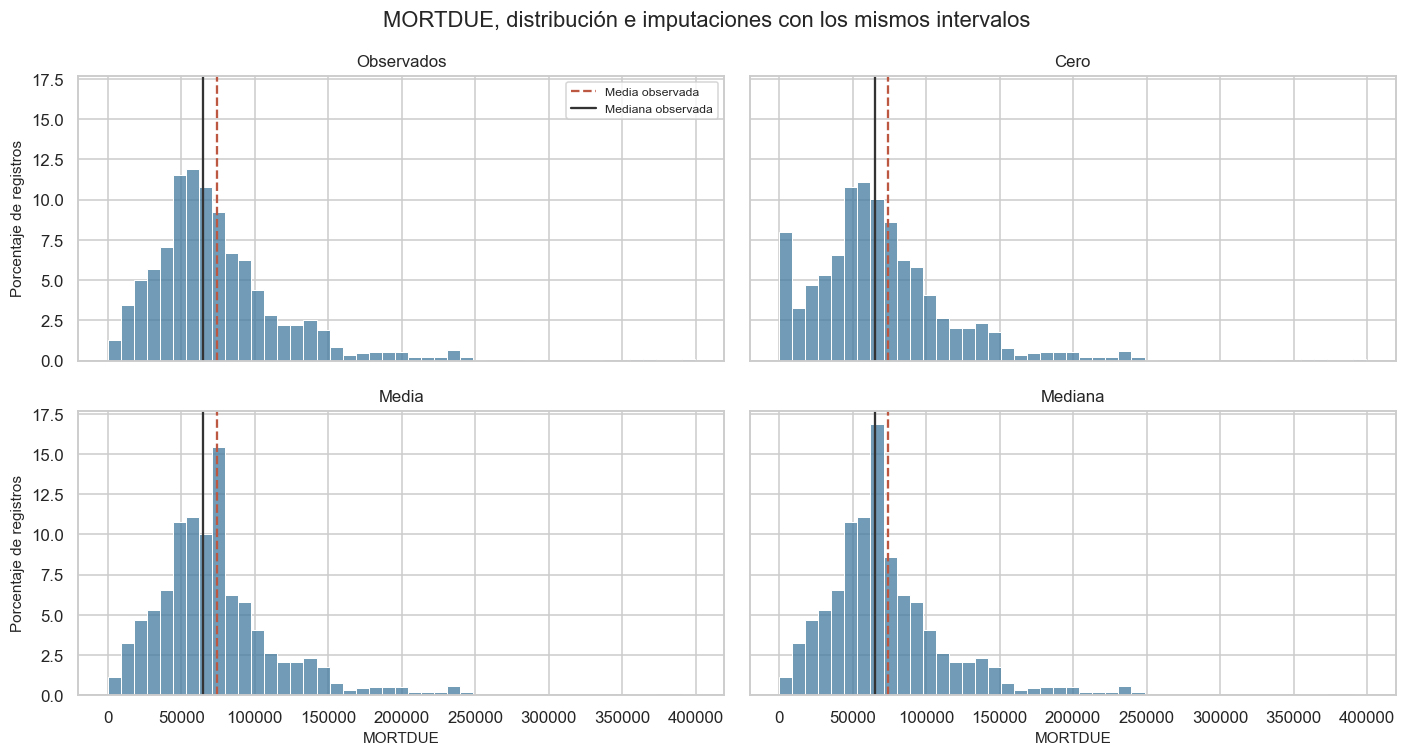

In [20]:
display(estadisticas.loc[['MORTDUE']].round(3))
display(resumen_validacion.loc['MORTDUE'].round(2))
display(cambios_distribucion.loc['MORTDUE'].round(3))
graficar_histogramas('MORTDUE')

### VALUE: imputación con la media
Aplicaremos la media de los valores observados después de ambos filtros a los 89 nulos conservados.
La media es sensible a la cola derecha y minimiza el error cuadrático entre reemplazos constantes.
El histograma muestra la concentración que introduce este reemplazo; `VALUE_FALTANTE` conserva su origen.

,count,mean,std,min,25%,50%,75%,max,nulos,nulos_pct,ceros_observados_pct,asimetria,iqr,limite_inferior_iqr,limite_superior_iqr,fuera_iqr
VALUE,5588.0,102783.767,57950.357,8000.0,66684.5,89908.5,120615.5,855909.0,89,1.568,0.0,3.064,53931.0,-14212.0,201512.0,308


,mae_medio,mae_sd,rmse_medio,rmse_sd
metodo,,,,
Cero,103049.87,952.64,117731.82,2127.39
Media,39920.27,1002.53,56870.97,3627.43
Mediana,38300.36,976.69,58391.80,3588.53
Mediana condicional,18903.05,674.63,34608.14,5252.64


,media,mediana,desviacion,asimetria,ceros_pct,varianza_relativa,wasserstein
metodo,,,,,,,
Observados,102783.767,89908.5,57950.357,3.064,0.000,1.000,0.000
Cero,101172.396,89231.0,58895.173,2.871,1.568,1.033,1611.371
Media,102783.767,90555.0,57494.229,3.088,0.000,0.984,625.996
Mediana,102581.918,89908.5,57516.476,3.095,0.000,0.985,600.101
Mediana condicional,102759.729,89908.5,57774.520,3.051,0.000,0.994,148.295


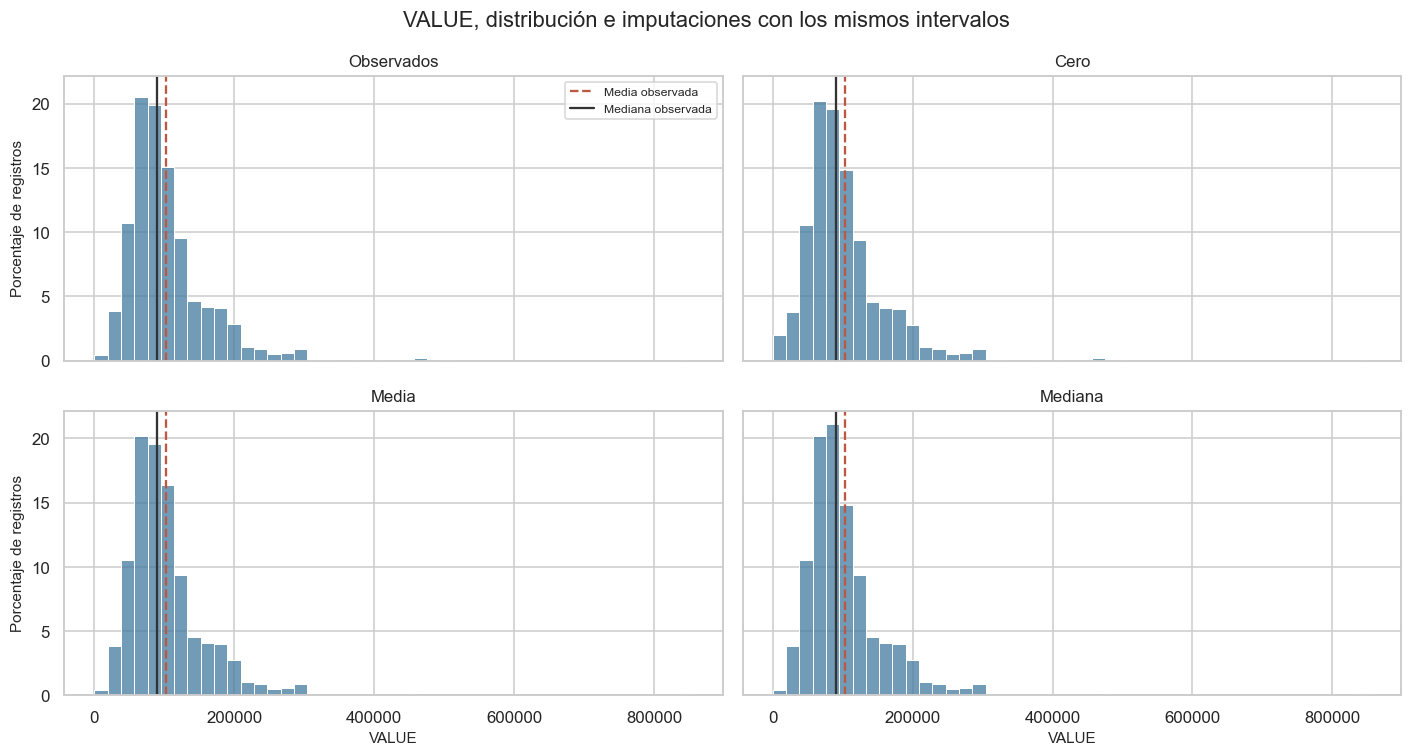

In [21]:
display(estadisticas.loc[['VALUE']].round(3))
display(resumen_validacion.loc['VALUE'].round(2))
display(cambios_distribucion.loc['VALUE'].round(3))
graficar_histogramas('VALUE')

La relación entre `MORTDUE` y `VALUE` permite estudiar una mediana condicional como alternativa.
Los gráficos y errores siguientes pertenecen a esa comparación y no cambian la política final.
La limpieza definitiva seguirá usando cero en `MORTDUE` y media en `VALUE`.

,MORTDUE,VALUE
MORTDUE,1.000,0.859
VALUE,0.859,1.000


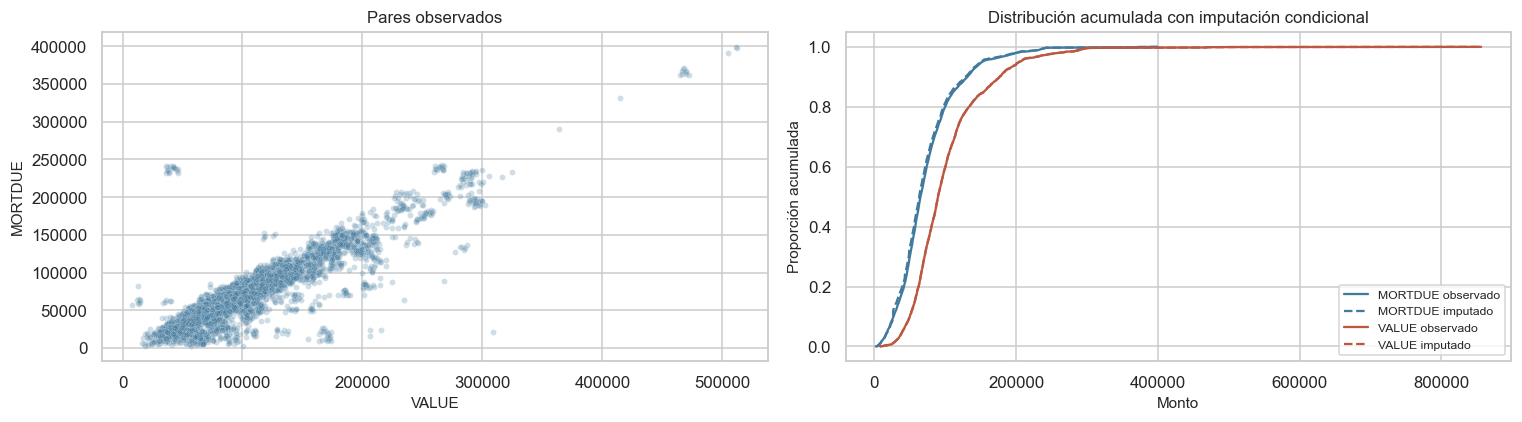

In [22]:
display(datita_base[['MORTDUE', 'VALUE']].corr(method='spearman').round(3))
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.scatterplot(data=datita_base, x='VALUE', y='MORTDUE', alpha=0.25, s=15, ax=axes[0], color='#427a9e')
axes[0].set_title('Pares observados')
for variable, color in [('MORTDUE', '#427a9e'), ('VALUE', '#bc5742')]:
    observados = datita_base[variable].dropna().sort_values()
    completos = escenarios[variable]['Mediana condicional'].sort_values()
    axes[1].plot(observados, np.arange(1, len(observados) + 1) / len(observados), label=f'{variable} observado', color=color)
    axes[1].plot(completos, np.arange(1, len(completos) + 1) / len(completos), label=f'{variable} imputado', color=color, linestyle='--')
axes[1].set(title='Distribución acumulada con imputación condicional', xlabel='Monto', ylabel='Proporción acumulada')
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

Resumimos el cambio de MAE de la mediana condicional frente a la mediana global.
También contamos cuántos nulos tienen una referencia observada y cuántos necesitan respaldo.
La mejora experimental se limita a valores observados ocultados al azar.

In [23]:
resumen_condicional = []
for variable, referencia in referencias.items():
    error_base = resumen_validacion.loc[(variable, 'Mediana'), 'mae_medio']
    error_condicional = resumen_validacion.loc[(variable, 'Mediana condicional'), 'mae_medio']
    resumen_condicional.append({'variable': variable, 'referencia': referencia, 'mejora_mae_vs_mediana_pct': (1 - error_condicional / error_base) * 100, 'nulos_con_referencia': int((datita_base[variable].isna() & datita_base[referencia].notna()).sum()), 'nulos_con_respaldo_global': int((datita_base[variable].isna() & datita_base[referencia].isna()).sum())})
display(pd.DataFrame(resumen_condicional).set_index('variable').round(2))

,referencia,mejora_mae_vs_mediana_pct,nulos_con_referencia,nulos_con_respaldo_global
variable,,,,
MORTDUE,VALUE,52.51,376,11
VALUE,MORTDUE,50.65,78,11


### REASON y JOB: categoría explícita
Comparamos `Not specified`, moda y eliminación de nulos en cada variable categórica.
Conservaremos `Not specified`; `Other` seguirá representando una ocupación informada.
Los porcentajes de cada alternativa usan su propio número de registros.

,Not specified,Moda,Eliminar nulos
REASON,,,
DebtCon,67.24,70.16,69.26
HomeImp,29.84,29.84,30.74
Not specified,2.92,0.00,0.00


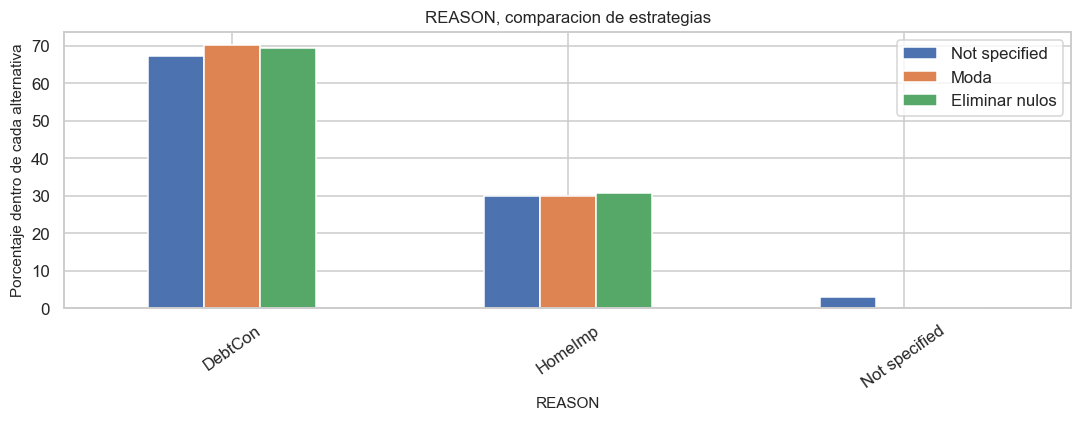

,Not specified,Moda,Eliminar nulos
JOB,,,
Mgr,13.19,13.19,13.54
Not specified,2.59,0.00,0.00
Office,16.52,16.52,16.96
Other,40.41,43.00,41.48
ProfExe,22.04,22.04,22.62
Sales,1.92,1.92,1.97
Self,3.33,3.33,3.42


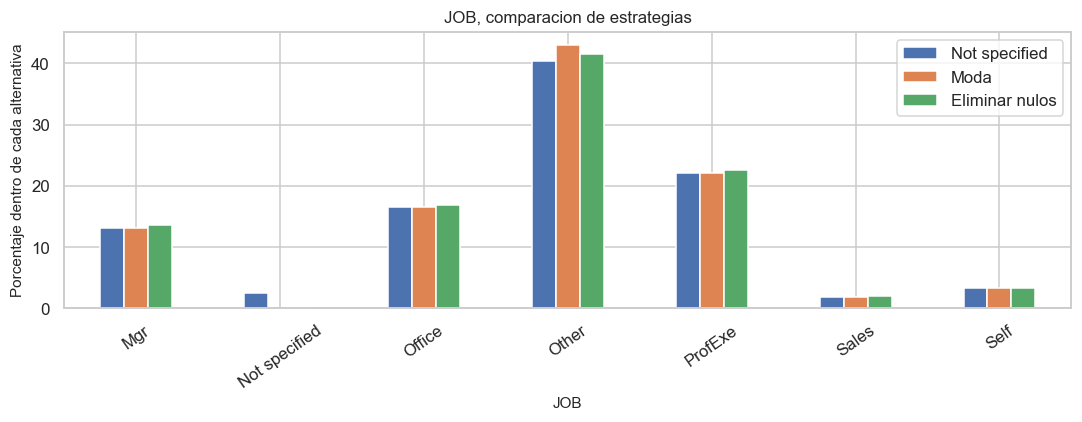

In [24]:
for variable in categoricas:
    original_categoria = datita_base[variable]
    categorias_comparadas = pd.DataFrame({'Not specified': original_categoria.fillna('Not specified').value_counts(normalize=True) * 100, 'Moda': original_categoria.fillna(original_categoria.mode().iloc[0]).value_counts(normalize=True) * 100, 'Eliminar nulos': original_categoria.dropna().value_counts(normalize=True) * 100}).fillna(0).sort_index()
    display(categorias_comparadas.round(2))
    ax = categorias_comparadas.plot.bar(figsize=(10, 4), rot=35)
    ax.set(title=f'{variable}, comparacion de estrategias', xlabel=variable, ylabel='Porcentaje dentro de cada alternativa')
    plt.tight_layout()
    plt.show()

Describimos la proporción de `BAD` por categoría y su intervalo de Wilson del 95 %.
Los tamaños de cada categoría acompañan las tasas para evitar interpretar porcentajes sin contexto.
Estas asociaciones históricas no constituyen reglas de clasificación ni evidencia causal.

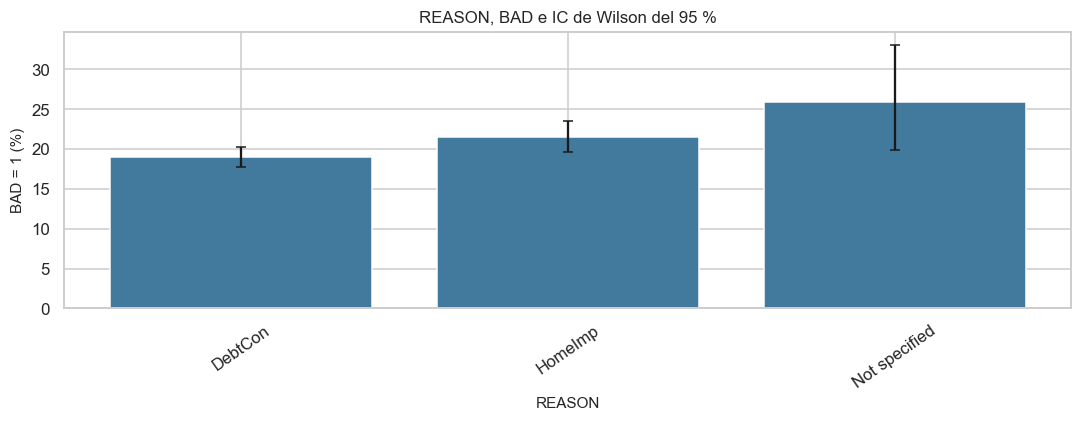

,clientes,malos,tasa_bad
categoria,,,
DebtCon,3817,723,18.94
HomeImp,1694,365,21.55
Not specified,166,43,25.90


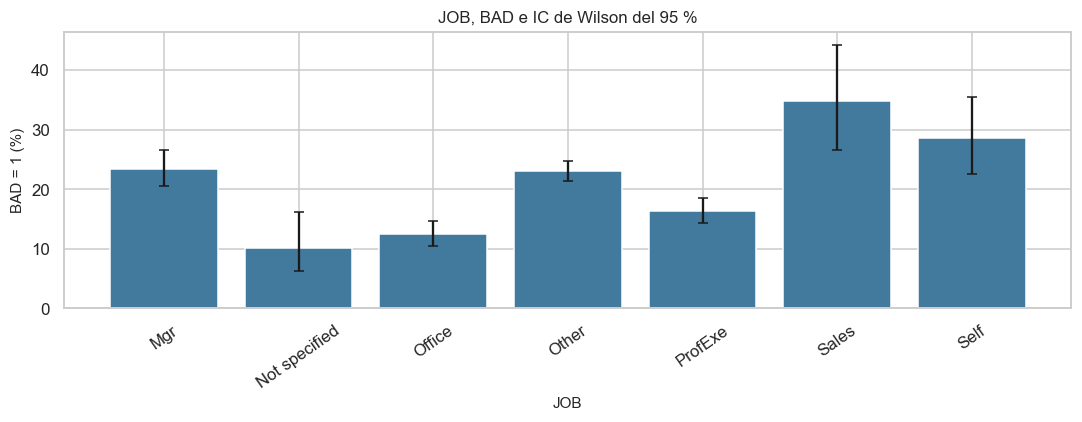

,clientes,malos,tasa_bad
categoria,,,
Mgr,749,175,23.36
Not specified,147,15,10.20
Office,938,117,12.47
Other,2294,528,23.02
ProfExe,1251,204,16.31
Sales,109,38,34.86
Self,189,54,28.57


In [25]:
for variable in categoricas:
    original_categoria = datita_base[variable]
    perfil_categoria = datita_base.assign(categoria=original_categoria.fillna('Not specified')).groupby('categoria')['BAD'].agg(clientes='size', malos='sum', tasa_bad='mean')
    intervalos = [binomtest(int(fila.malos), int(fila.clientes)).proportion_ci(confidence_level=0.95, method='wilson') for fila in perfil_categoria.itertuples()]
    errores = np.array([[fila.tasa_bad - intervalo.low, intervalo.high - fila.tasa_bad] for fila, intervalo in zip(perfil_categoria.itertuples(), intervalos)]).T * 100
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.bar(perfil_categoria.index, perfil_categoria['tasa_bad'] * 100, color='#427a9e', yerr=errores, capsize=3)
    ax.set(title=f'{variable}, BAD e IC de Wilson del 95 %', xlabel=variable, ylabel='BAD = 1 (%)')
    ax.tick_params(axis='x', rotation=35)
    plt.tight_layout()
    plt.show()
    perfil_categoria['tasa_bad'] *= 100
    display(perfil_categoria.round(2))

### YOJ: cero y conversión a meses
Aplicaremos cero a los 351 nulos; la bandera distinguirá ausencia de antigüedad observada igual a cero.
`YOJ_MONTHS = YOJ * 12` conserva las fracciones: 1,5 años equivalen a 18 meses.
Después de estandarizar, años y meses son equivalentes. Usaremos solo meses en K-means.
La tabla y las barras permiten comparar unidades y estrategias de imputación.

,Años,Meses
Media,8.9692,107.6300
Mediana,7.0000,84.0000
Desviación,7.6050,91.2600
Asimetría,0.9808,0.9808


estandarizacion_equivalente    True
nulos_originales                351
ceros_observados                401
dtype: object

,mae_medio,mae_sd,rmse_medio,rmse_sd
metodo,,,,
Cero,8.973,0.219,11.687,0.216
Media,5.997,0.103,7.491,0.119
Mediana,5.863,0.134,7.745,0.151


,media,mediana,desviacion,asimetria,ceros_pct,varianza_relativa,wasserstein
metodo,,,,,,,
Observados,8.969,7.0,7.605,0.981,7.529,1.000,0.000
Cero,8.415,6.0,7.676,1.013,13.246,1.019,0.555
Media,8.969,8.0,7.366,1.013,7.064,0.938,0.376
Mediana,8.847,7.0,7.381,1.055,7.064,0.942,0.367


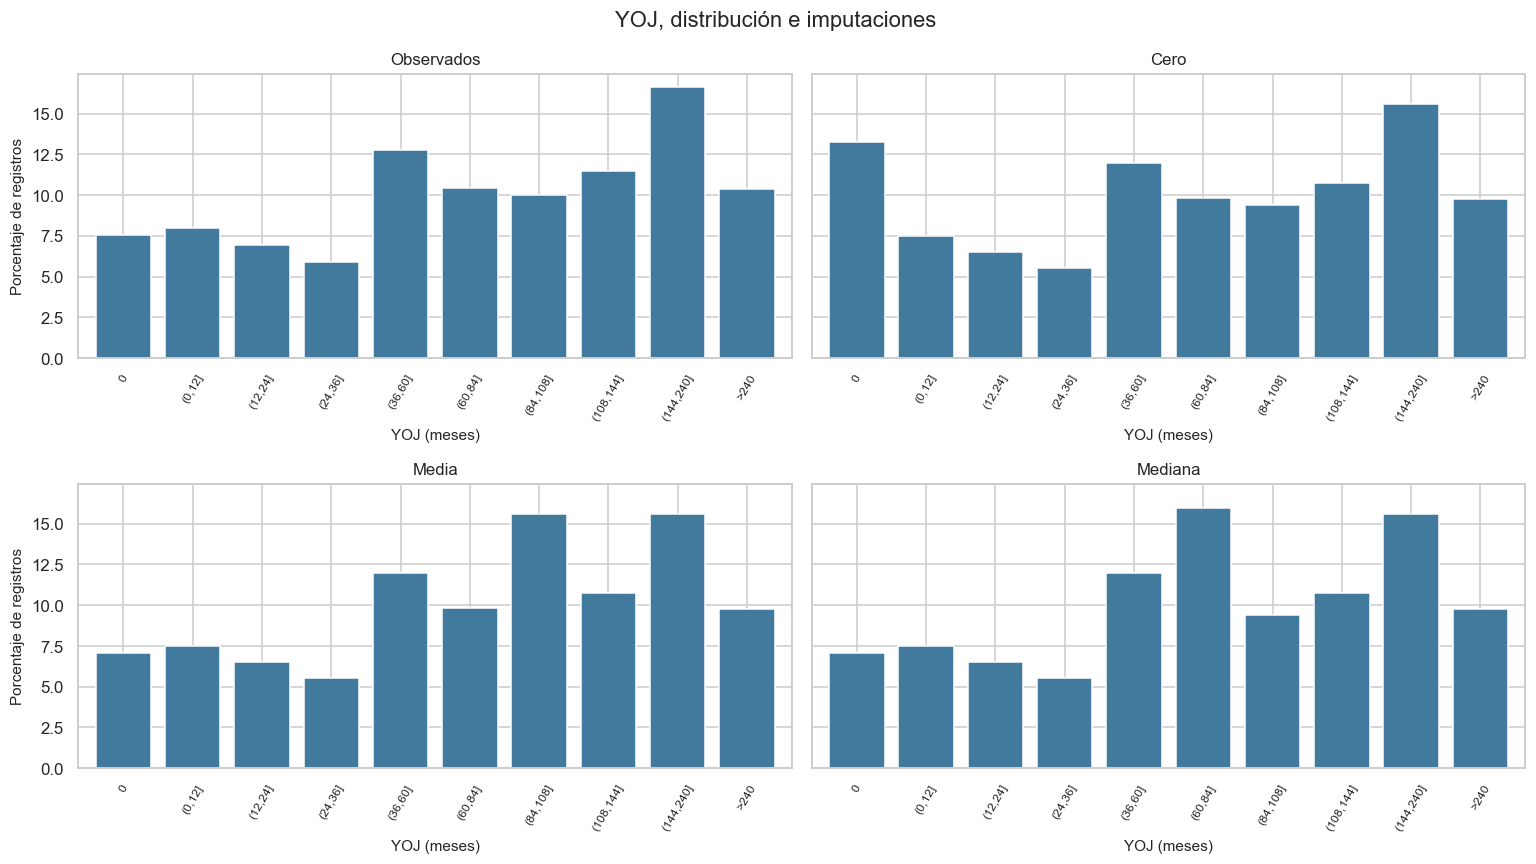

In [26]:
yoj_observado = datita_base['YOJ'].dropna()
comparacion_unidades = pd.DataFrame({'Años': [yoj_observado.mean(), yoj_observado.median(), yoj_observado.std(), yoj_observado.skew()], 'Meses': [(yoj_observado * 12).mean(), (yoj_observado * 12).median(), (yoj_observado * 12).std(), (yoj_observado * 12).skew()]}, index=['Media', 'Mediana', 'Desviación', 'Asimetría'])
display(comparacion_unidades.round(4))
z_anios = (yoj_observado - yoj_observado.mean()) / yoj_observado.std()
z_meses = (yoj_observado * 12 - (yoj_observado * 12).mean()) / (yoj_observado * 12).std()
display(pd.Series({'estandarizacion_equivalente': np.allclose(z_anios, z_meses), 'nulos_originales': int(datita_base['YOJ'].isna().sum()), 'ceros_observados': int(datita_base['YOJ'].eq(0).sum())}))
display(resumen_validacion.loc['YOJ'].round(3))
display(cambios_distribucion.loc['YOJ'].round(3))
limites_yoj = [-0.001, 0, 12, 24, 36, 60, 84, 108, 144, 240, np.inf]
etiquetas_yoj = ['0', '(0,12]', '(12,24]', '(24,36]', '(36,60]', '(60,84]', '(84,108]', '(108,144]', '(144,240]', '>240']
graficar_barras('YOJ', limites=limites_yoj, etiquetas=etiquetas_yoj, factor=12)

### DEROG: mediana
La mediana observada es cero, por lo que los 427 nulos recibirán ese reemplazo.
Es una elección robusta para minimizar el error absoluto de una constante en una distribución concentrada.
La bandera evita interpretar una ausencia imputada como un historial negativo observado igual a cero.

,count,mean,std,min,25%,50%,75%,max,nulos,nulos_pct,ceros_observados_pct,asimetria,iqr,limite_inferior_iqr,limite_superior_iqr,fuera_iqr
DEROG,5250.0,0.253,0.842,0.0,0.0,0.0,0.0,10.0,427,7.522,86.229,5.336,0.0,0.0,0.0,723


,mae_medio,mae_sd,rmse_medio,rmse_sd
metodo,,,,
Cero,0.255,0.031,0.876,0.091
Media,0.438,0.022,0.838,0.087
Mediana,0.255,0.031,0.876,0.091


,media,mediana,desviacion,asimetria,ceros_pct,varianza_relativa,wasserstein
metodo,,,,,,,
Observados,0.253,0.0,0.842,5.336,86.229,1.000,0.000
Cero,0.234,0.0,0.813,5.560,87.264,0.931,0.019
Media,0.253,0.0,0.810,5.548,79.743,0.925,0.033
Mediana,0.234,0.0,0.813,5.560,87.264,0.931,0.019


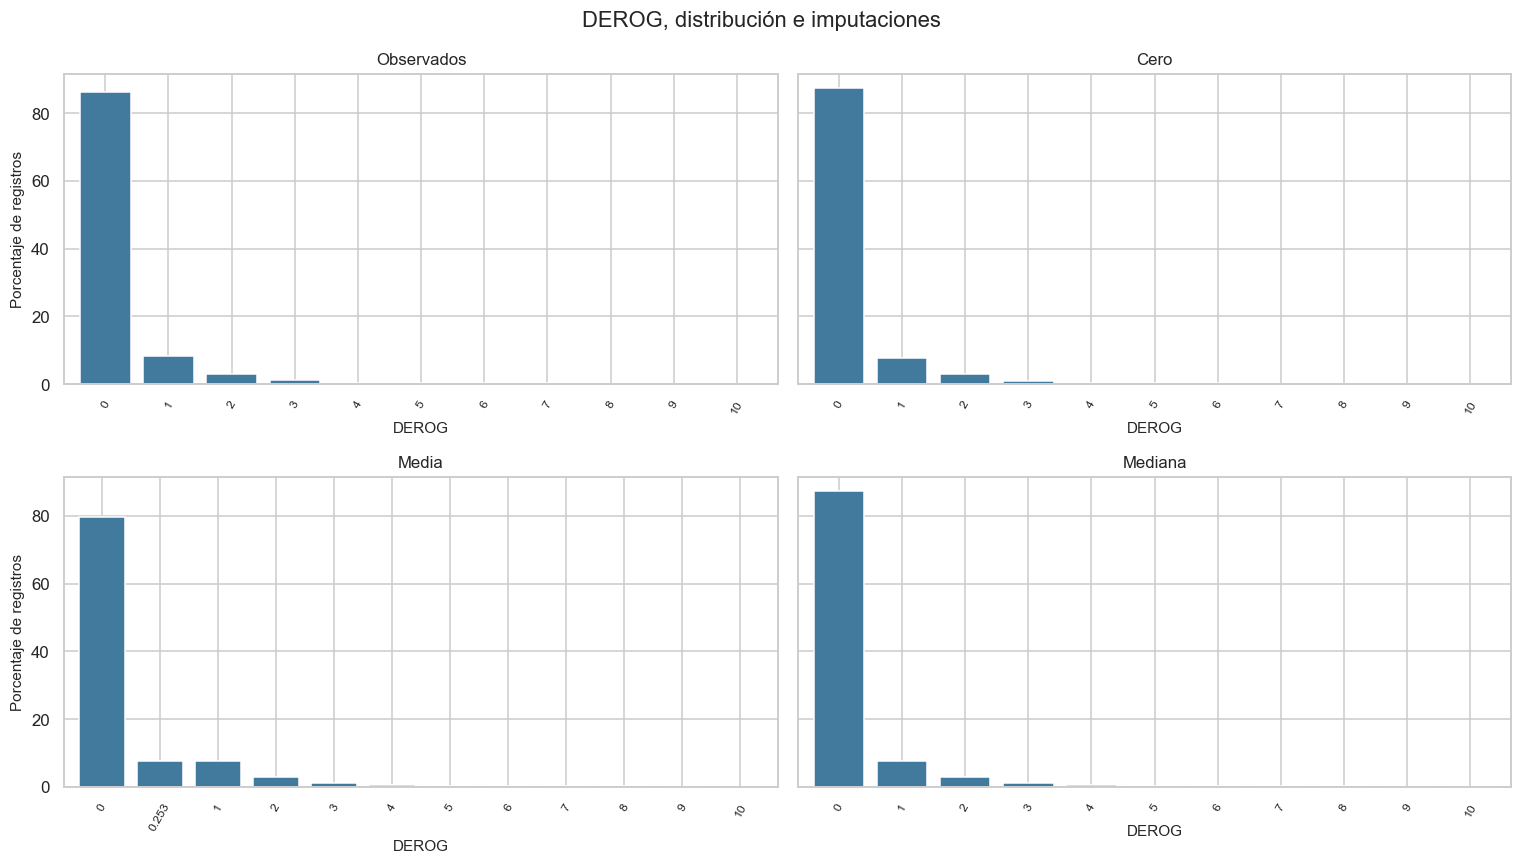

In [27]:
display(estadisticas.loc[['DEROG']].round(3))
display(resumen_validacion.loc['DEROG'].round(3))
display(cambios_distribucion.loc['DEROG'].round(3))
graficar_barras('DEROG')

### DELINQ: mediana
Aplicaremos la mediana observada, que vale cero, a los 298 nulos conservados tras incluir esta variable en ambos filtros.
La comparación muestra el efecto sobre los conteos y su concentración en cero.
La media introduciría un conteo fraccionario. La bandera conservará la ausencia original.

,count,mean,std,min,25%,50%,75%,max,nulos,nulos_pct,ceros_observados_pct,asimetria,iqr,limite_inferior_iqr,limite_superior_iqr,fuera_iqr
DELINQ,5379.0,0.449,1.127,0.0,0.0,0.0,0.0,15.0,298,5.249,77.691,4.025,0.0,0.0,0.0,1200


,mae_medio,mae_sd,rmse_medio,rmse_sd
metodo,,,,
Cero,0.441,0.022,1.201,0.064
Media,0.694,0.013,1.117,0.062
Mediana,0.441,0.022,1.201,0.064


,media,mediana,desviacion,asimetria,ceros_pct,varianza_relativa,wasserstein
metodo,,,,,,,
Observados,0.449,0.0,1.127,4.025,77.691,1.000,0.000
Cero,0.426,0.0,1.102,4.145,78.862,0.955,0.024
Media,0.449,0.0,1.097,4.135,73.613,0.947,0.037
Mediana,0.426,0.0,1.102,4.145,78.862,0.955,0.024


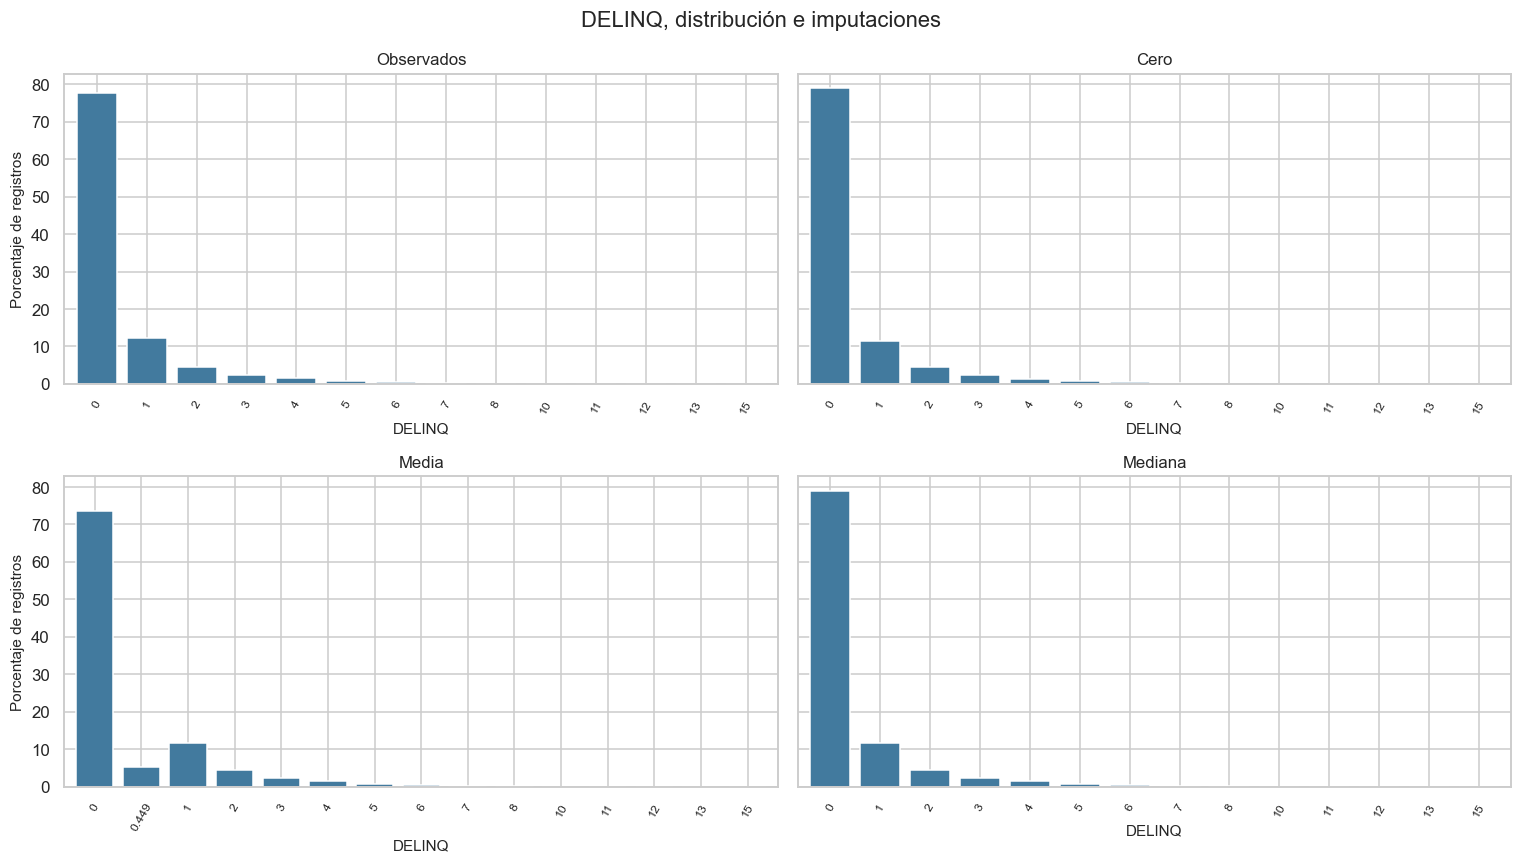

In [28]:
display(estadisticas.loc[['DELINQ']].round(3))
display(resumen_validacion.loc['DELINQ'].round(3))
display(cambios_distribucion.loc['DELINQ'].round(3))
graficar_barras('DELINQ')

### NINQ: mediana
La mediana observada es uno y se aplicará a los 232 nulos conservados.
El reemplazo mantiene un conteo entero y limita la influencia de la cola derecha.
La tabla permite comprobar sus errores frente a cero y media.

,count,mean,std,min,25%,50%,75%,max,nulos,nulos_pct,ceros_observados_pct,asimetria,iqr,limite_inferior_iqr,limite_superior_iqr,fuera_iqr
NINQ,5445.0,1.186,1.729,0.0,0.0,1.0,2.0,17.0,232,4.087,46.446,2.621,2.0,-3.0,5.0,177


,mae_medio,mae_sd,rmse_medio,rmse_sd
metodo,,,,
Cero,1.168,0.031,2.050,0.076
Media,1.183,0.031,1.685,0.076
Mediana,1.103,0.034,1.693,0.078


,media,mediana,desviacion,asimetria,ceros_pct,varianza_relativa,wasserstein
metodo,,,,,,,
Observados,1.186,1.0,1.729,2.621,46.446,1.000,0.000
Cero,1.138,1.0,1.710,2.672,48.635,0.978,0.048
Media,1.186,1.0,1.694,2.676,44.548,0.959,0.049
Mediana,1.179,1.0,1.694,2.688,44.548,0.960,0.046


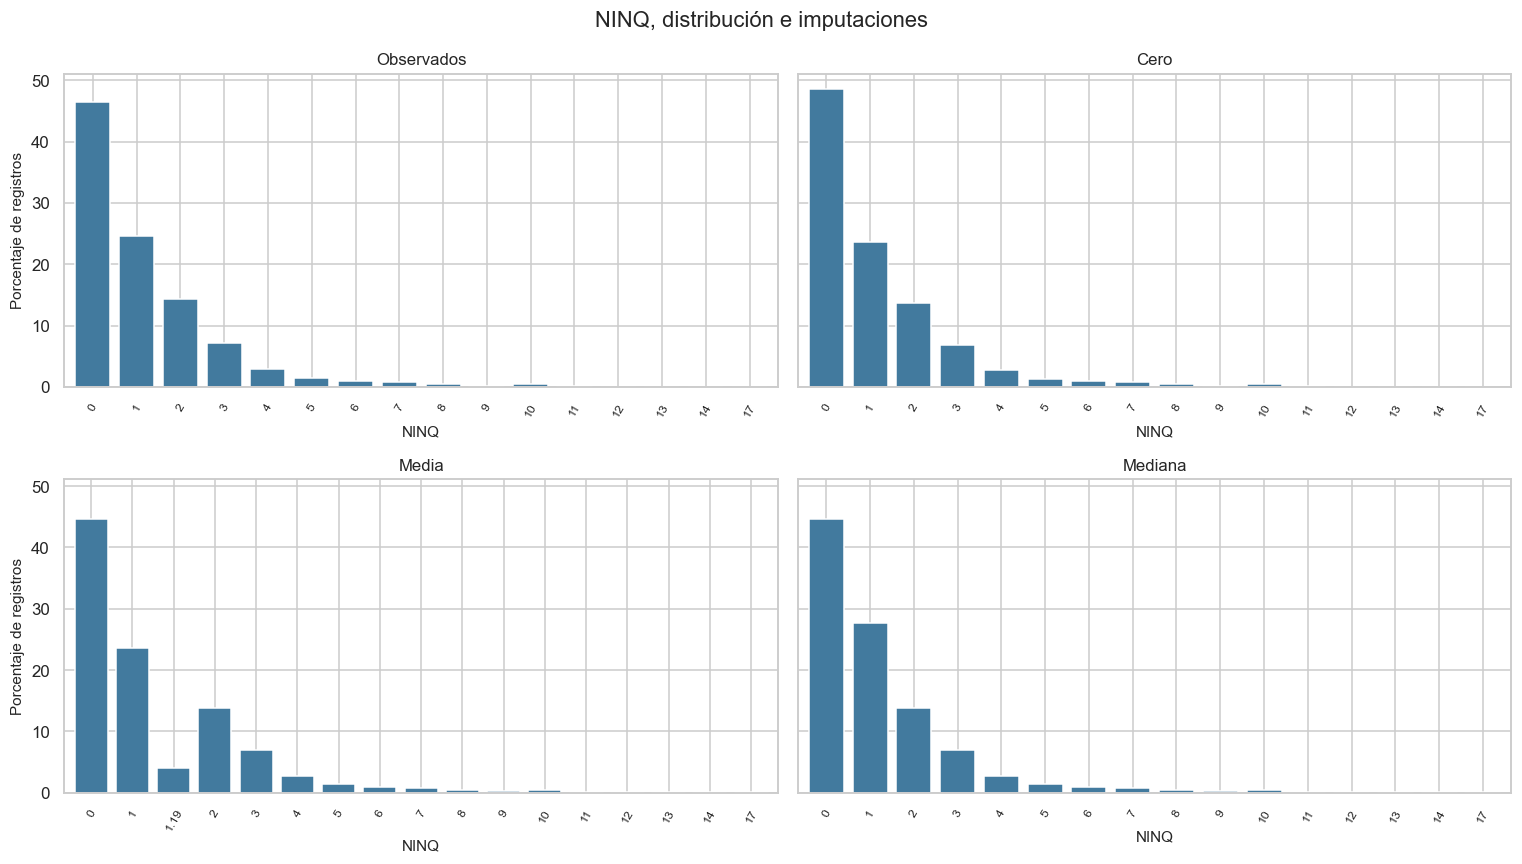

In [29]:
display(estadisticas.loc[['NINQ']].round(3))
display(resumen_validacion.loc['NINQ'].round(3))
display(cambios_distribucion.loc['NINQ'].round(3))
graficar_barras('NINQ')

### CLAGE: cero
Aplicaremos cero a los 86 nulos por la política del proyecto y conservaremos la unidad en meses.
El reemplazo no demuestra que la línea crediticia acabe de abrirse; la bandera conserva esa distinción.
Los valores observados superiores a 900 meses se señalan para revisar su origen y se conservan.

,count,mean,std,min,25%,50%,75%,max,nulos,nulos_pct,ceros_observados_pct,asimetria,iqr,limite_inferior_iqr,limite_superior_iqr,fuera_iqr
CLAGE,5591.0,179.624,85.569,0.0,115.452,173.5,230.719,1168.234,86,1.515,0.036,1.36,115.267,-57.447,403.619,53


,mae_medio,mae_sd,rmse_medio,rmse_sd
metodo,,,,
Cero,178.527,2.861,197.236,4.085
Media,65.927,2.067,83.870,4.355
Mediana,65.666,2.101,83.992,4.517


,media,mediana,desviacion,asimetria,ceros_pct,varianza_relativa,wasserstein
metodo,,,,,,,
Observados,179.624,173.500,85.569,1.360,0.036,1.000,0.000
Cero,176.903,171.622,87.707,1.207,1.550,1.051,2.721
Media,179.624,174.621,84.918,1.371,0.035,0.985,1.010
Mediana,179.531,173.500,84.921,1.374,0.035,0.985,1.007


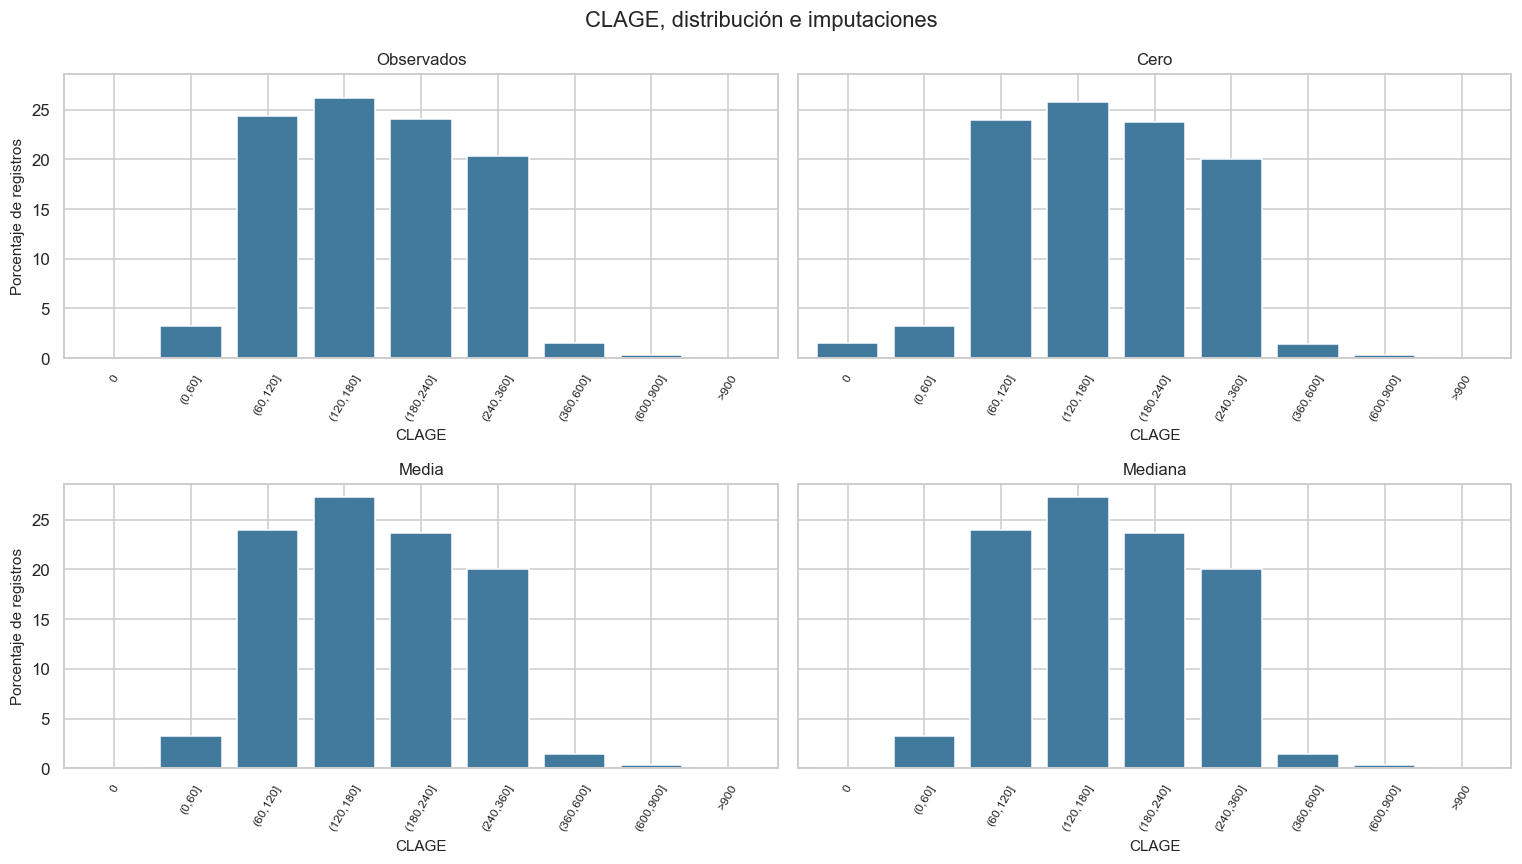

,BAD,CLAGE,CLNO,YOJ
3097,1,1154.633333,0.0,3.0
3679,1,1168.233561,0.0,3.0


In [30]:
display(estadisticas.loc[['CLAGE']].round(3))
display(resumen_validacion.loc['CLAGE'].round(3))
display(cambios_distribucion.loc['CLAGE'].round(3))
limites_clage = [-0.001, 0, 60, 120, 180, 240, 360, 600, 900, np.inf]
etiquetas_clage = ['0', '(0,60]', '(60,120]', '(120,180]', '(180,240]', '(240,360]', '(360,600]', '(600,900]', '>900']
graficar_barras('CLAGE', limites=limites_clage, etiquetas=etiquetas_clage)
display(datita_base.loc[datita_base['CLAGE'] > 900, ['BAD', 'CLAGE', 'CLNO', 'YOJ']])

### CLNO: política de imputación con cero
Después de ambos filtros no quedan nulos en `CLNO`; su política de cero se conserva, pero no requiere reemplazos.
Mantenemos la comparación de métodos con valores observados ocultados para entender sus efectos.
`CLNO_FALTANTE` queda en cero para todas las solicitudes conservadas y no aporta diferencias a la distancia.

,count,mean,std,min,25%,50%,75%,max,nulos,nulos_pct,ceros_observados_pct,asimetria,iqr,limite_inferior_iqr,limite_superior_iqr,fuera_iqr
CLNO,5677.0,21.362,10.155,0.0,15.0,20.0,26.0,71.0,0,0.0,1.092,0.765,11.0,-1.5,42.5,219


,mae_medio,mae_sd,rmse_medio,rmse_sd
metodo,,,,
Cero,21.434,0.223,23.764,0.267
Media,7.867,0.138,10.264,0.223
Mediana,7.833,0.143,10.362,0.238


,media,mediana,desviacion,asimetria,ceros_pct,varianza_relativa,wasserstein
metodo,,,,,,,
Observados,21.362,20.0,10.155,0.765,1.092,1.0,0.0
Cero,21.362,20.0,10.155,0.765,1.092,1.0,0.0
Media,21.362,20.0,10.155,0.765,1.092,1.0,0.0
Mediana,21.362,20.0,10.155,0.765,1.092,1.0,0.0


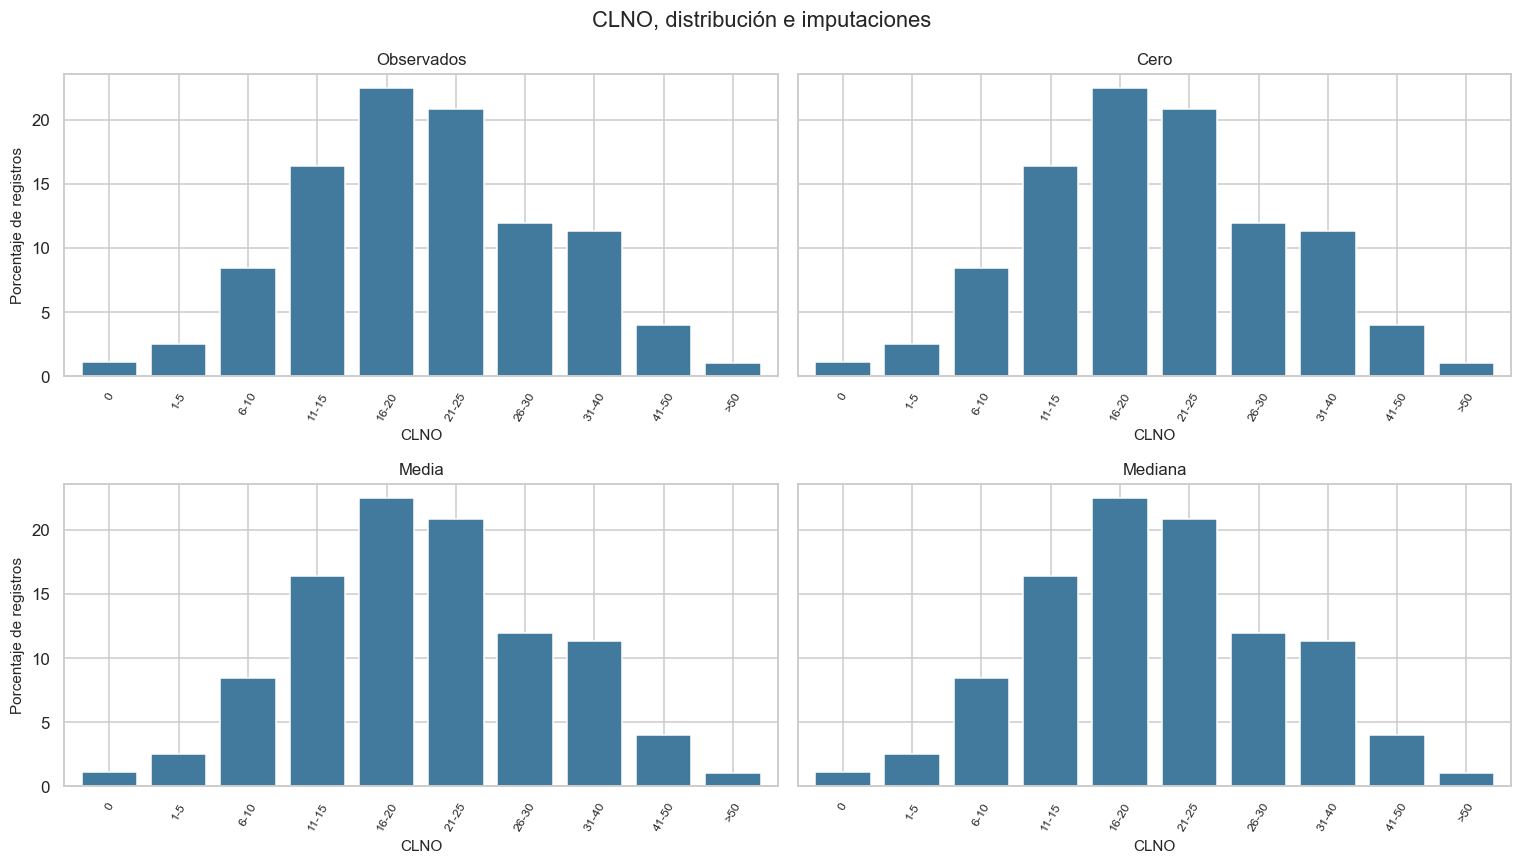

In [31]:
display(estadisticas.loc[['CLNO']].round(3))
display(resumen_validacion.loc['CLNO'].round(3))
display(cambios_distribucion.loc['CLNO'].round(3))
limites_clno = [-0.001, 0, 5, 10, 15, 20, 25, 30, 40, 50, np.inf]
etiquetas_clno = ['0', '1-5', '6-10', '11-15', '16-20', '21-25', '26-30', '31-40', '41-50', '>50']
graficar_barras('CLNO', limites=limites_clno, etiquetas=etiquetas_clno)

### DEBTINC: análisis con nulos conservados
Quedan 1188 nulos, aproximadamente el 20,93 % de las 5677 filas conservadas.
Estudiamos sus distribuciones y alternativas de imputación, pero no aplicamos ningún reemplazo final.
Se guardan los datos observados, los nulos y su bandera para análisis. Ambos quedan fuera de K-means.
La exclusión es una decisión del proyecto; no existe un umbral universal de nulos que la imponga.

,count,mean,std,min,25%,50%,75%,max,nulos,nulos_pct,ceros_observados_pct,asimetria,iqr,limite_inferior_iqr,limite_superior_iqr,fuera_iqr
DEBTINC,4489.0,33.963,8.598,0.524,29.328,34.976,39.111,203.312,1188,20.927,0.0,2.998,9.784,14.652,53.786,89


,mae_medio,mae_sd,rmse_medio,rmse_sd
metodo,,,,
Cero,33.903,0.296,35.041,0.467
Media,5.927,0.137,8.812,1.096
Mediana,5.878,0.152,8.880,1.077


,media,mediana,desviacion,asimetria,ceros_pct,varianza_relativa,wasserstein
metodo,,,,,,,
Observados,33.963,34.976,8.598,2.998,0.000,1.000,0.000
Cero,26.855,32.313,15.791,-0.259,20.927,3.373,7.107
Media,33.963,33.963,7.645,3.371,0.000,0.791,1.244
Mediana,34.175,34.976,7.656,3.273,0.000,0.793,1.231


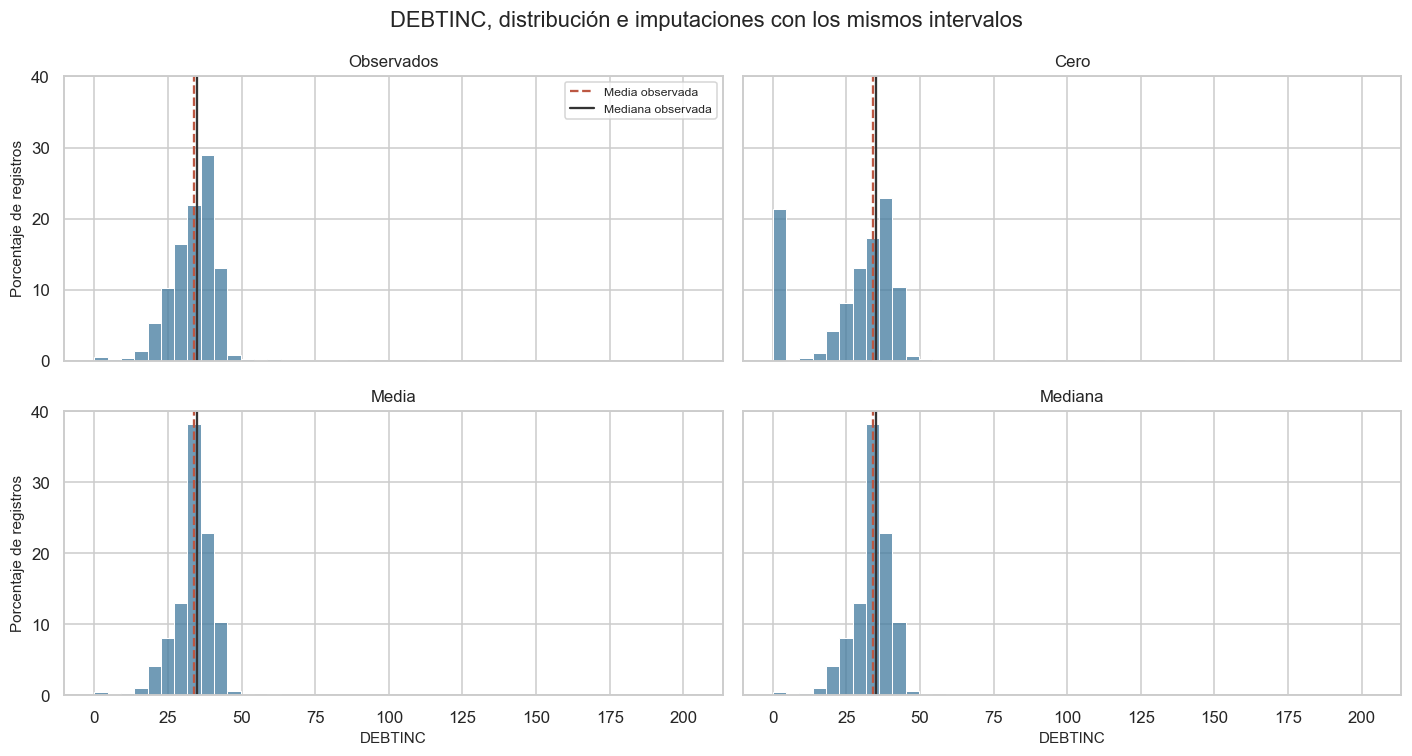

In [32]:
display(estadisticas.loc[['DEBTINC']].round(3))
display(resumen_validacion.loc['DEBTINC'].round(3))
display(cambios_distribucion.loc['DEBTINC'].round(3))
graficar_histogramas('DEBTINC')

## 7. Relaciones entre variables
La correlación de Spearman utiliza rangos de pares observados y describe relaciones monotónicas.
`MORTDUE` y `VALUE` aportan información relacionada: incluir ambas da más peso al componente patrimonial.
`DEBTINC` participa en este análisis exploratorio, aunque no se utilizará en el modelado.

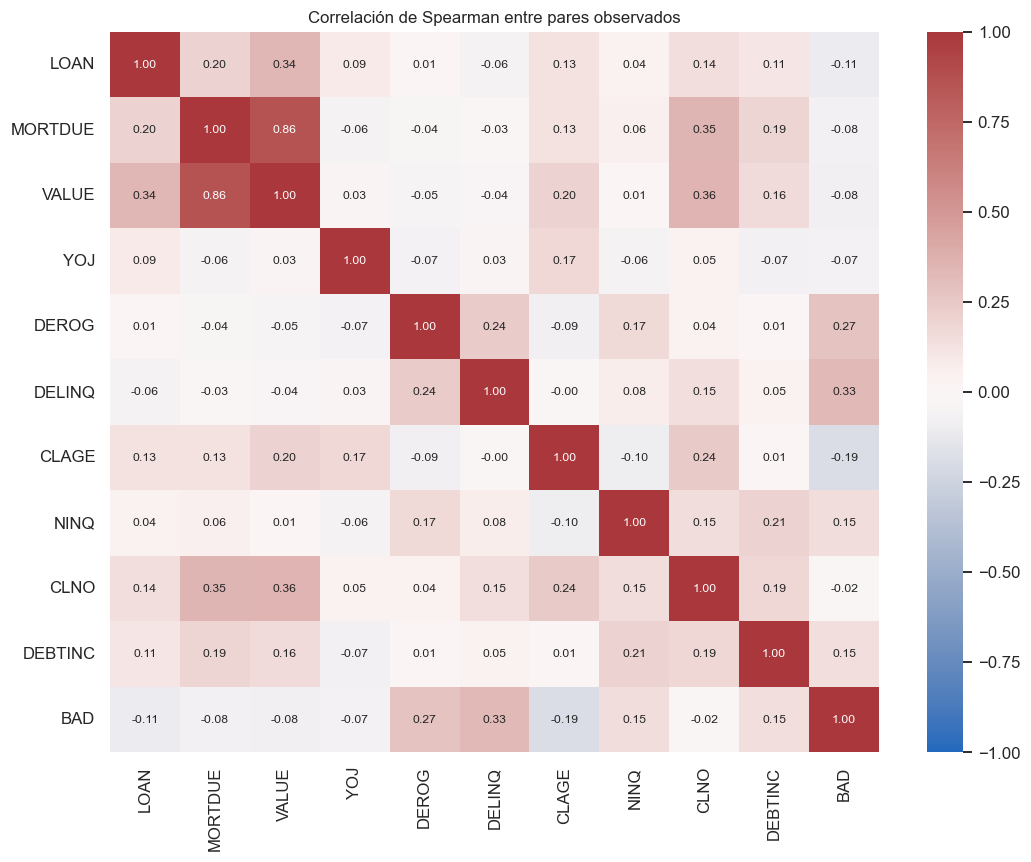

In [33]:
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(datita_base[numericas + ['BAD']].corr(method='spearman'), annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, center=0, ax=ax, annot_kws={'fontsize': 8})
ax.set_title('Correlación de Spearman entre pares observados')
plt.tight_layout()
plt.show()

## 8. Limpieza definitiva
Copiamos las 5677 solicitudes conservadas y añadimos `ID_FILA` con su posición original en el CSV.
Creamos las banderas antes de imputar para registrar qué celdas eran desconocidas.
Las categorías ausentes reciben `Not specified`. Los valores originales observados se conservarán.

In [34]:
datita_limpia = datita_base.copy(deep=True)
datita_limpia.insert(0, 'ID_FILA', datita_base.index.to_numpy())
for variable in variables_con_banderas:
    datita_limpia[f'{variable}_FALTANTE'] = datita_base[variable].isna().astype('int8')


for variable in categoricas:
    datita_limpia[variable] = datita_limpia[variable].fillna('Not specified')
datita_limpia[categoricas] = datita_limpia[categoricas].astype('category')

Aplicamos exactamente las imputaciones acordadas, calculadas después de aplicar ambos filtros.
`VALUE` usa la media; `DEROG`, `DELINQ` y `NINQ` usan la mediana; las otras cinco variables reciben cero.
`DEBTINC` no aparece en el diccionario de reemplazos y mantiene sus nulos.
La tabla registra el método, el reemplazo y la cantidad de nulos tratados por variable.

In [35]:
metodos_imputacion = {'MORTDUE': 'Cero', 'VALUE': 'Media', 'YOJ': 'Cero', 'DEROG': 'Mediana', 'DELINQ': 'Mediana', 'NINQ': 'Mediana', 'CLAGE': 'Cero', 'CLNO': 'Cero'}
reemplazos = {variable: 0 if metodo == 'Cero' else datita_base[variable].mean() if metodo == 'Media' else datita_base[variable].median() for variable, metodo in metodos_imputacion.items()}
datita_limpia = datita_limpia.fillna(reemplazos)
decisiones = pd.DataFrame({'estrategia': pd.Series(metodos_imputacion), 'reemplazo': pd.Series(reemplazos), 'nulos_tratados': datita_base.isna().sum()}).dropna(subset=['estrategia'])


display(decisiones)
print(f'DEBTINC conserva {datita_limpia["DEBTINC"].isna().sum()} nulos para analisis y se excluye del modelado.')

DEBTINC conserva 1188 nulos para analisis y se excluye del modelado.


,estrategia,reemplazo,nulos_tratados
CLAGE,Cero,0.000000,86
CLNO,Cero,0.000000,0
DELINQ,Mediana,0.000000,298
DEROG,Mediana,0.000000,427
MORTDUE,Cero,0.000000,387
NINQ,Mediana,1.000000,232
VALUE,Media,102783.767187,89
YOJ,Cero,0.000000,351


Convertimos los conteos a enteros, conservamos `YOJ` en años y añadimos su equivalente en meses.
Las dos banderas de revisión de `CLAGE` se calculan con datos observados, antes de la imputación.
Así evitamos atribuir a los datos originales contradicciones creadas por un cero de reemplazo.

In [36]:
datita_limpia[conteos] = datita_limpia[conteos].astype('int64')
datita_limpia['BAD'] = datita_limpia['BAD'].astype('int8')
datita_limpia['YOJ_MONTHS'] = datita_limpia['YOJ'] * 12
datita_limpia['CLAGE_MAYOR_900_MESES'] = datita_base['CLAGE'].gt(900).astype('int8')
datita_limpia['CLAGE_CLNO_REVISAR'] = (datita_base['CLNO'].eq(0) & datita_base['CLAGE'].gt(0)).astype('int8')


assert datita_limpia.drop(columns='DEBTINC').notna().all().all()
assert datita_limpia['DEBTINC'].isna().equals(datita_base['DEBTINC'].isna())
assert len(datita_limpia) == len(datita_base) and datita_limpia['ID_FILA'].is_unique
assert datita_limpia['VALUE'].gt(0).all()
assert datita_limpia[numericas].drop(columns='DEBTINC').ge(0).all().all()

Verificamos que cada valor conocido se conserve y que cada bandera reproduzca la ausencia original.
Para las celdas imputadas, contrastamos el resultado con el reemplazo acordado.
Estas comprobaciones evitan alteraciones silenciosas de la limpieza y permiten revisar sus supuestos.

In [37]:
for variable in numericas + categoricas + ['BAD']:
    observados = datita_base[variable].notna()
    assert datita_limpia.loc[observados, variable].eq(datita_base.loc[observados, variable]).all()
for variable in variables_con_banderas:
    assert datita_limpia[f'{variable}_FALTANTE'].eq(datita_base[variable].isna().astype(int)).all()
for variable, reemplazo in reemplazos.items():
    ausentes = datita_base[variable].isna()
    assert datita_limpia.loc[ausentes, variable].eq(reemplazo).all()

Guardamos el parquet limpio con unidades originales, banderas y los nulos de `DEBTINC`.
Lo leemos de nuevo para verificar contenido y tipos. El índice interno no se exporta porque ya existe `ID_FILA`.
Para un clasificador futuro se deberá seleccionar explícitamente sus predictores y excluir `DEBTINC`.

In [38]:
ruta_limpio = f'{ruta_outputs}/hmeq_limpio.parquet'
datita_limpia.to_parquet(ruta_limpio, index=False)
pd.testing.assert_frame_equal(datita_limpia.reset_index(drop=True), pd.read_parquet(ruta_limpio))


display(datita_limpia.head())
print(f'Parquet limpio guardado en {ruta_limpio}')

Parquet limpio guardado en ../outputs/hmeq_limpio.parquet


,ID_FILA,BAD,LOAN,MORTDUE,VALUE,REASON,JOB,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC,MORTDUE_FALTANTE,VALUE_FALTANTE,REASON_FALTANTE,JOB_FALTANTE,YOJ_FALTANTE,DEROG_FALTANTE,DELINQ_FALTANTE,CLAGE_FALTANTE,NINQ_FALTANTE,CLNO_FALTANTE,DEBTINC_FALTANTE,YOJ_MONTHS,CLAGE_MAYOR_900_MESES,CLAGE_CLNO_REVISAR
0,0,1,1100,25860.0,39025.0,HomeImp,Other,10.5,0,0,94.366667,1,9,NaN,0,0,0,0,0,0,0,0,0,0,1,126.0,0,0
1,1,1,1300,70053.0,68400.0,HomeImp,Other,7.0,0,2,121.833333,0,14,NaN,0,0,0,0,0,0,0,0,0,0,1,84.0,0,0
2,2,1,1500,13500.0,16700.0,HomeImp,Other,4.0,0,0,149.466667,1,10,NaN,0,0,0,0,0,0,0,0,0,0,1,48.0,0,0
4,4,0,1700,97800.0,112000.0,HomeImp,Office,3.0,0,0,93.333333,0,14,NaN,0,0,0,0,0,0,0,0,0,0,1,36.0,0,0
5,5,1,1700,30548.0,40320.0,HomeImp,Other,9.0,0,0,101.466002,1,8,37.113614,0,0,0,0,0,0,0,0,0,0,0,108.0,0,0


## 9. Matriz para K-means
Aplicamos `log1p` a los montos y tres conteos con colas largas, y usamos meses para la antigüedad laboral.
La matriz incluye nueve variables numéricas y excluye `BAD`, identificadores y los indicadores de revisión.
`DEBTINC` y `DEBTINC_FALTANTE` se excluyen para que la segmentación no dependa de esa variable.
Conservamos las ocho banderas numéricas del esquema original; la de `CLNO` es constante y no altera las distancias.

In [39]:
variables_log = ['LOAN', 'MORTDUE', 'VALUE', 'DEROG', 'DELINQ', 'NINQ']
variables_lineales = ['YOJ_MONTHS', 'CLAGE', 'CLNO']
numericas_kmeans = variables_log + variables_lineales
banderas_kmeans = [f'{variable}_FALTANTE' for variable in numericas_a_comparar if variable != 'DEBTINC']
variables_kmeans = numericas_kmeans + categoricas + banderas_kmeans
X_kmeans = datita_limpia[variables_kmeans].copy()
X_kmeans[variables_log] = np.log1p(X_kmeans[variables_log])


excluidas_kmeans = ['BAD', 'ID_FILA', 'YOJ', 'DEBTINC', 'DEBTINC_FALTANTE', 'CLAGE_MAYOR_900_MESES', 'CLAGE_CLNO_REVISAR']
assert not set(excluidas_kmeans).intersection(X_kmeans.columns)
assert X_kmeans.notna().all().all()

Estandarizamos las nueve magnitudes numéricas para compararlas en escalas similares.
Codificamos las categorías con one-hot completo y dejamos las banderas en 0/1.
La elección de estos bloques define la distancia: las categorías y los datos ausentes también influyen.
Las transformaciones se aplican sobre una copia; los parquets conservan las unidades interpretables.
[Preprocesamiento de scikit-learn](https://scikit-learn.org/stable/modules/preprocessing.html)

In [40]:
escalador = StandardScaler()
numericas_escaladas = pd.DataFrame(escalador.fit_transform(X_kmeans[numericas_kmeans]), columns=numericas_kmeans, index=X_kmeans.index)
categorias_codificadas = pd.get_dummies(X_kmeans[categoricas], dtype=float)
datos_kmeans = pd.concat([numericas_escaladas, categorias_codificadas, X_kmeans[banderas_kmeans]], axis=1)
matriz_kmeans = datos_kmeans.to_numpy(dtype=float)
assert np.isfinite(matriz_kmeans).all()


display(datos_kmeans.head().round(3))
print(f'Matriz de segmentacion con {matriz_kmeans.shape[0]} solicitudes y {matriz_kmeans.shape[1]} columnas transformadas')

Matriz de segmentacion con 5677 solicitudes y 27 columnas transformadas


,LOAN,MORTDUE,VALUE,DEROG,DELINQ,NINQ,YOJ_MONTHS,CLAGE,CLNO,REASON_DebtCon,REASON_HomeImp,REASON_Not specified,JOB_Mgr,JOB_Not specified,JOB_Office,JOB_Other,JOB_ProfExe,JOB_Sales,JOB_Self,MORTDUE_FALTANTE,VALUE_FALTANTE,YOJ_FALTANTE,DEROG_FALTANTE,DELINQ_FALTANTE,CLAGE_FALTANTE,NINQ_FALTANTE,CLNO_FALTANTE
0,-4.684,-0.041,-1.693,-0.351,-0.471,0.199,0.272,-0.941,-1.217,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0
1,-4.392,0.308,-0.567,-0.351,1.962,-0.952,-0.184,-0.628,-0.725,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0
2,-4.143,-0.270,-3.397,-0.351,-0.471,0.199,-0.575,-0.313,-1.119,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0
4,-3.924,0.425,0.423,-0.351,-0.471,-0.952,-0.705,-0.953,-0.725,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0
5,-3.924,0.017,-1.628,-0.351,-0.471,0.199,0.076,-0.860,-1.316,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0


## 10. Ajuste, método del codo y análisis de silueta
Probamos de 2 a 10 grupos con 20 inicializaciones K-means++ y semilla fija.
Conservamos el modelo con mayor silueta media sobre todas las solicitudes.
Complementamos la tabla con la curva de inercia y el diagrama de siluetas individuales del modelo elegido.
La mejor silueta de esta búsqueda no garantiza grupos naturales y las figuras ayudan a revisar su separación.
[K-means](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html) y [silueta](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_samples.html).

In [41]:
resultados_k = []
mejor_silueta = -np.inf
with threadpool_limits(limits=2), config_context(working_memory=128):
    for k in range(2, 11):
        modelo = KMeans(n_clusters=k, init='k-means++', n_init=20, max_iter=500, random_state=semilla)
        etiquetas = modelo.fit_predict(matriz_kmeans)
        siluetas_k = silhouette_samples(matriz_kmeans, etiquetas)
        silueta = siluetas_k.mean()
        if silueta > mejor_silueta:
            mejor_silueta = silueta
            kmeans = modelo
            valores_silueta = siluetas_k
        tamanios = np.bincount(etiquetas, minlength=k)
        resultados_k.append({'k': k, 'inercia': modelo.inertia_, 'silueta': silueta, 'grupo_minimo': tamanios.min(), 'grupo_maximo': tamanios.max()})

Mostramos la selección en una tabla y conservamos las siluetas individuales del modelo elegido.
Una silueta cercana a cero indica solapamiento y una negativa sugiere mayor proximidad media a otro grupo.
El resultado depende de los predictores, sus transformaciones y el conjunto de valores de k probado.
Las siguientes figuras permiten contrastar esa elección con la curva de inercia y la separación dentro de cada grupo.

In [42]:
metricas_k = pd.DataFrame(resultados_k).set_index('k')
k_optimo = int(metricas_k['silueta'].idxmax())
assert kmeans.n_clusters == k_optimo


display(metricas_k.round(4))
display(pd.Series({'grupos_elegidos': k_optimo, 'silueta_media': valores_silueta.mean(), 'silueta_mediana': np.median(valores_silueta), 'silueta_negativa_pct': (valores_silueta < 0).mean() * 100}))
print(f'Se eligieron {k_optimo} grupos por silueta media ({mejor_silueta:.4f}).')

Se eligieron 4 grupos por silueta media (0.1312).


,inercia,silueta,grupo_minimo,grupo_maximo
k,,,,
2,52869.6191,0.1134,2378,3299
3,47497.6315,0.1232,383,2839
4,43248.9599,0.1312,363,2575
5,40300.2984,0.1286,363,2090
6,37886.4288,0.1305,363,1873
7,36000.9405,0.1214,362,1420
8,34794.9692,0.1210,361,1288
9,33756.5357,0.1112,361,1004
10,32948.4782,0.1072,332,895


grupos_elegidos          4.000000
silueta_media            0.131211
silueta_mediana          0.130635
silueta_negativa_pct    11.907698
dtype: float64

### Gráfica del método del codo
La inercia es la suma de distancias cuadráticas a los centroides de cada grupo.
Para k=1 calculamos directamente la distancia al centroide global y completamos la curva de 1 a 10.
El codo sugiere dónde disminuye la mejora al añadir grupos; no se estima automáticamente un codo.
La línea vertical señala la elección por silueta y no afirma que ese punto sea un codo inequívoco.
Guardamos la figura en `../outputs/kmeans_codo.png`.

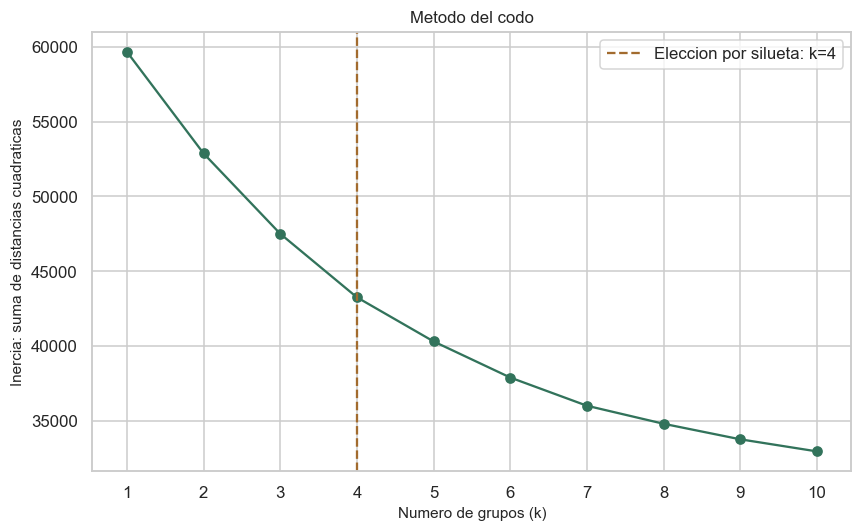

In [43]:
inercia_un_grupo = np.square(matriz_kmeans - matriz_kmeans.mean(axis=0)).sum()
inercia_codo = pd.concat([pd.Series({1: inercia_un_grupo}), metricas_k['inercia']]).sort_index()


fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(inercia_codo.index, inercia_codo.values, marker='o', color='#32735b')
ax.axvline(k_optimo, color='#a26b2e', linestyle='--', label=f'Eleccion por silueta: k={k_optimo}')
ax.set(title='Metodo del codo', xlabel='Numero de grupos (k)', ylabel='Inercia: suma de distancias cuadraticas')
ax.set_xticks(inercia_codo.index)
ax.legend()
plt.tight_layout()
fig.savefig(f'{ruta_outputs}/kmeans_codo.png', dpi=180, bbox_inches='tight')
plt.show()

### Diagrama de silueta de los grupos elegidos
Cada banda representa un grupo con sus coeficientes individuales ordenados de menor a mayor.
Su altura refleja el número de solicitudes y su anchura el valor de silueta de cada fila.
Los valores negativos indican solicitudes más próximas, en promedio, a otro grupo.
La línea discontinua marca la silueta media global; los colores y la leyenda identifican los grupos.
Guardamos la figura en `../outputs/kmeans_silueta.png`.

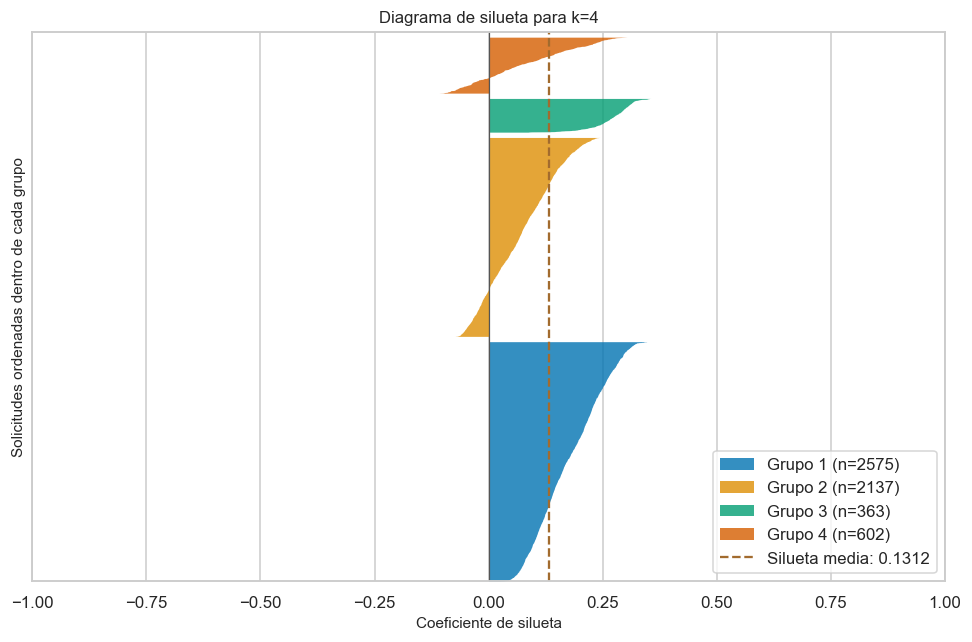

In [44]:
fig, ax = plt.subplots(figsize=(9, 6))
inicio = 0
colores_grupos = sns.color_palette('colorblind', n_colors=k_optimo)
for grupo in range(k_optimo):
    siluetas_grupo = np.sort(valores_silueta[kmeans.labels_ == grupo])
    fin = inicio + siluetas_grupo.size
    ax.fill_betweenx(np.arange(inicio, fin), 0, siluetas_grupo, facecolor=colores_grupos[grupo], alpha=0.8, linewidth=0, label=f'Grupo {grupo + 1} (n={siluetas_grupo.size})')
    inicio = fin + max(20, int(len(matriz_kmeans) / 100))


ax.axvline(mejor_silueta, color='#a26b2e', linestyle='--', label=f'Silueta media: {mejor_silueta:.4f}')
ax.axvline(0, color='#555555', linewidth=0.8)
ax.set(title=f'Diagrama de silueta para k={k_optimo}', xlabel='Coeficiente de silueta', ylabel='Solicitudes ordenadas dentro de cada grupo', yticks=[])
ax.set_xlim(-1, 1)
ax.set_ylim(0, inicio)
ax.legend(loc='lower right')
plt.tight_layout()
fig.savefig(f'{ruta_outputs}/kmeans_silueta.png', dpi=180, bbox_inches='tight')
plt.show()

## 11. Identificación de solicitudes y perfiles
Asignamos etiquetas desde 1 y guardamos la silueta de cada solicitud en la misma posición de su matriz.
Los números identifican grupos y no establecen un orden de riesgo.
Incorporamos `BAD` después del ajuste para describir tasas históricas y tamaños de los grupos.

In [45]:
datita_grupos = datita_limpia.copy()
datita_grupos['GRUPO'] = kmeans.labels_ + 1
datita_grupos['SILUETA'] = valores_silueta
perfil_grupos = datita_grupos.groupby('GRUPO').agg(clientes=('ID_FILA', 'size'), malos=('BAD', 'sum'), tasa_bad_pct=('BAD', 'mean'), silueta_media=('SILUETA', 'mean'))
perfil_grupos['porcentaje'] = perfil_grupos['clientes'] / len(datita_grupos) * 100
perfil_grupos['tasa_bad_pct'] *= 100


intervalos_grupos = [binomtest(int(fila.malos), int(fila.clientes)).proportion_ci(confidence_level=0.95, method='wilson') for fila in perfil_grupos.itertuples()]
perfil_grupos['bad_ic95_inf'] = [intervalo.low * 100 for intervalo in intervalos_grupos]
perfil_grupos['bad_ic95_sup'] = [intervalo.high * 100 for intervalo in intervalos_grupos]
display(perfil_grupos.round(3))

,clientes,malos,tasa_bad_pct,silueta_media,porcentaje,bad_ic95_inf,bad_ic95_sup
GRUPO,,,,,,,
1,2575,485,18.835,0.176,45.358,17.372,20.391
2,2137,267,12.494,0.068,37.643,11.159,13.964
3,363,66,18.182,0.270,6.394,14.554,22.476
4,602,313,51.993,0.078,10.604,48.002,55.959


Describimos medianas, categorías y ausencia de información mediante tablas.
`DEBTINC` se resume únicamente con sus valores observados y se acompaña de su cantidad disponible.
Las medias estandarizadas identifican los rasgos numéricos más marcados de cada grupo.

In [46]:
medianas_grupos = datita_grupos.groupby('GRUPO')[numericas + ['YOJ_MONTHS']].median()
ausencias_grupos = datita_grupos.groupby('GRUPO')[[f'{variable}_FALTANTE' for variable in variables_con_banderas]].mean() * 100
categorias_grupos = pd.crosstab(datita_grupos['GRUPO'], datita_grupos['REASON'], normalize='index') * 100
trabajos_grupos = pd.crosstab(datita_grupos['GRUPO'], datita_grupos['JOB'], normalize='index') * 100
perfil_escalado = numericas_escaladas.assign(GRUPO=datita_grupos['GRUPO']).groupby('GRUPO').mean()
debtinc_grupos = datita_grupos.groupby('GRUPO')['DEBTINC'].agg(observados='count', mediana_observada='median')


display(medianas_grupos.round(2))
display(ausencias_grupos.round(2))
display(categorias_grupos.round(2))
display(trabajos_grupos.round(2))
display(debtinc_grupos.round(2))

,LOAN,MORTDUE,VALUE,YOJ,DEROG,DELINQ,CLAGE,NINQ,CLNO,DEBTINC,YOJ_MONTHS
GRUPO,,,,,,,,,,,
1,13000.0,56067.0,78275.0,5.0,0.0,0.0,128.00,1.0,17.0,34.48,60.0
2,22400.0,88810.0,122273.0,10.0,0.0,0.0,218.10,1.0,25.0,36.19,120.0
3,15600.0,0.0,57156.0,3.0,0.0,0.0,165.55,0.0,11.0,30.68,36.0
4,16100.0,59374.0,85400.0,5.0,1.0,0.0,140.86,1.0,21.0,34.95,60.0


,MORTDUE_FALTANTE,VALUE_FALTANTE,REASON_FALTANTE,JOB_FALTANTE,YOJ_FALTANTE,DEROG_FALTANTE,DELINQ_FALTANTE,CLAGE_FALTANTE,NINQ_FALTANTE,CLNO_FALTANTE,DEBTINC_FALTANTE
GRUPO,,,,,,,,,,,
1,0.00,0.78,2.56,2.72,4.93,7.65,4.78,2.14,4.31,0.0,20.08
2,0.19,1.12,2.25,1.08,4.73,9.31,4.77,0.00,2.95,0.0,15.82
3,100.00,2.75,8.26,10.47,20.11,8.54,10.19,6.61,6.06,0.0,20.39
4,3.32,5.81,3.65,2.66,8.31,0.00,5.98,1.16,5.98,0.0,43.02


REASON,DebtCon,HomeImp,Not specified
GRUPO,,,
1,65.17,32.27,2.56
2,74.31,23.44,2.25
3,36.64,55.10,8.26
4,69.44,26.91,3.65


JOB,Mgr,Not specified,Office,Other,ProfExe,Sales,Self
GRUPO,,,,,,,
1,9.59,2.72,19.81,46.25,17.24,2.33,2.06
2,17.69,1.08,14.04,28.83,32.76,0.89,4.73
3,6.89,10.47,16.25,56.47,3.86,2.75,3.31
4,16.45,2.66,11.46,46.84,15.45,3.32,3.82


,observados,mediana_observada
GRUPO,,
1,2058,34.48
2,1799,36.19
3,289,30.68
4,343,34.95


Escribimos una descripción breve por grupo con sus rasgos numéricos y categorías más frecuentes.
Las desviaciones se refieren a las magnitudes transformadas y estandarizadas, no a las unidades originales.
Los perfiles son una base exploratoria para revisar solicitudes y desarrollar heurísticas posteriores.

In [47]:
descripciones = []
for grupo, perfil in perfil_grupos.iterrows():
    diferencias = perfil_escalado.loc[grupo].reindex(perfil_escalado.loc[grupo].abs().sort_values(ascending=False).index).head(3)
    rasgos = ', '.join(f'{variable}: {valor:+.2f} desviaciones' for variable, valor in diferencias.items())
    trabajo_principal = trabajos_grupos.loc[grupo].idxmax()
    razon_principal = categorias_grupos.loc[grupo].idxmax()
    texto = f'Grupo {grupo}: {int(perfil.clientes)} solicitudes ({perfil.porcentaje:.1f} %). Rasgos principales: {rasgos}. Ocupacion mas frecuente: {trabajo_principal}. Motivo mas frecuente: {razon_principal}. BAD historico: {perfil.tasa_bad_pct:.2f} %, con IC del 95 % de {perfil.bad_ic95_inf:.2f} a {perfil.bad_ic95_sup:.2f} %.'
    descripciones.append({'GRUPO': int(grupo), 'descripcion': texto})
    display(Markdown(texto))


descripciones_grupos = pd.DataFrame(descripciones).set_index('GRUPO')

Grupo 1: 2575 solicitudes (45.4 %). Rasgos principales: LOAN: -0.43 desviaciones, CLAGE: -0.41 desviaciones, CLNO: -0.40 desviaciones. Ocupacion mas frecuente: Other. Motivo mas frecuente: DebtCon. BAD historico: 18.83 %, con IC del 95 % de 17.37 a 20.39 %.

Grupo 2: 2137 solicitudes (37.6 %). Rasgos principales: VALUE: +0.66 desviaciones, CLNO: +0.60 desviaciones, CLAGE: +0.57 desviaciones. Ocupacion mas frecuente: ProfExe. Motivo mas frecuente: DebtCon. BAD historico: 12.49 %, con IC del 95 % de 11.16 a 13.96 %.

Grupo 3: 363 solicitudes (6.4 %). Rasgos principales: MORTDUE: -3.61 desviaciones, VALUE: -1.07 desviaciones, CLNO: -0.94 desviaciones. Ocupacion mas frecuente: Other. Motivo mas frecuente: HomeImp. BAD historico: 18.18 %, con IC del 95 % de 14.55 a 22.48 %.

Grupo 4: 602 solicitudes (10.6 %). Rasgos principales: DEROG: +2.55 desviaciones, DELINQ: +0.69 desviaciones, NINQ: +0.53 desviaciones. Ocupacion mas frecuente: Other. Motivo mas frecuente: DebtCon. BAD historico: 51.99 %, con IC del 95 % de 48.00 a 55.96 %.

## 12. Exportación de asignaciones y grupos
Guardamos un parquet general y un parquet por grupo con `ID_FILA`, variables limpias, banderas y etiquetas.
`DEBTINC` conserva sus nulos como dato de análisis y no ha participado en el ajuste.
PowerShell crea la carpeta del número de grupos elegido con una ruta relativa y comprobamos cada archivo.

In [48]:
ruta_asignaciones = f'{ruta_outputs}/hmeq_con_grupos.parquet'
ruta_grupos = f'{ruta_outputs}/grupos_kmeans_k{k_optimo}'
comando_grupos = f"New-Item -ItemType Directory -Force '{ruta_grupos}' | Out-Null"
run(['powershell', '-NoProfile', '-Command', comando_grupos], check=True, capture_output=True, text=True, creationflags=CREATE_NO_WINDOW)
datita_grupos.to_parquet(ruta_asignaciones, index=False)


archivos_grupos = []
for grupo, clientes_grupo in datita_grupos.groupby('GRUPO'):
    ruta_grupo = f'{ruta_grupos}/grupo_{grupo}.parquet'
    clientes_grupo.to_parquet(ruta_grupo, index=False)
    pd.testing.assert_frame_equal(clientes_grupo.reset_index(drop=True), pd.read_parquet(ruta_grupo))
    archivos_grupos.append({'grupo': int(grupo), 'clientes': len(clientes_grupo), 'archivo': ruta_grupo})
display(pd.DataFrame(archivos_grupos))

,grupo,clientes,archivo
0,1,2575,../outputs/grupos_kmeans_k4/grupo_1.parquet
1,2,2137,../outputs/grupos_kmeans_k4/grupo_2.parquet
2,3,363,../outputs/grupos_kmeans_k4/grupo_3.parquet
3,4,602,../outputs/grupos_kmeans_k4/grupo_4.parquet


Reconstruimos el conjunto desde los parquets para verificar una partición exacta de las filas conservadas.
Cada `ID_FILA` debe aparecer una sola vez y las 283 solicitudes eliminadas deben quedar fuera.
Comparamos valores y tipos con el resultado en memoria para verificar la exportación completa.

In [49]:
recuperados = pd.concat([pd.read_parquet(archivo['archivo']) for archivo in archivos_grupos], ignore_index=True).sort_values('ID_FILA').reset_index(drop=True)
assert recuperados['ID_FILA'].is_unique and len(recuperados) == len(datita_base)
assert recuperados['ID_FILA'].tolist() == datita_base.index.tolist()
assert not recuperados['ID_FILA'].isin(datita_original.index[filas_eliminadas]).any()
pd.testing.assert_frame_equal(datita_grupos.sort_values('ID_FILA').reset_index(drop=True), recuperados)
pd.testing.assert_frame_equal(datita_grupos.reset_index(drop=True), pd.read_parquet(ruta_asignaciones))


print(f'Se verificaron {len(recuperados)} registros repartidos en {k_optimo} archivos de grupo.')
print(f'El filtro elimino {cantidad_eliminada} filas: {porcentaje_eliminado:.4f} % de las {tamanio_original} originales.')

Se verificaron 5677 registros repartidos en 4 archivos de grupo.
El filtro elimino 283 filas: 4.7483 % de las 5960 originales.


## 13. Alcance y siguiente etapa
La limpieza y la segmentación describen la muestra conservada. Los ceros imputados expresan una política con bandera, no hechos observados.
`DEBTINC` permanece disponible para análisis y se excluye del modelado. El número de grupo no es una clase de riesgo.
Para evaluar un clasificador, partir del CSV y separar entrenamiento y prueba antes de estimar imputaciones, escalado o segmentos.
Si se usa un grupo como predictor, ajustar K-means solo con entrenamiento y asignar las demás solicitudes con `predict`.
Las tasas de `BAD` y sus intervalos son descriptivos; la búsqueda de k y las imputaciones requieren validación para cualquier uso predictivo.
[Prevención de fuga de información](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage)